# 観測と理論式の比較

このノートブックのモデルと範囲は `thesis_common.ipynb` で指定する。変更したら先頭のセルから実行し直す。

コメント中の `cell N` は分割前の `thesis.ipynb` の番号で、各セルの1行目の `[旧 cell N]` と対応する。

# file_gas
# r_cen_[i] :0 sigmag_[i] :1 sigmad_tot_[i] :2 sigmad_vapor : 3 vg_r_[i] : 4 vg_phi_[i] :5 vg_wind_[i] :6 vd_r_tot[i][0] : 7 
# lambda1_[i]: 8 lambda2_[i] :9 dsigmagdt_w[i]:10 T_[i]:11 P_[i][nz_s] : 12 P_[i][nz_s]/beta_disk_[i][nz_s] : 13 Q_toomre[i] : 14 alpha_GI[i] : 15  
# alpha_phiz[i] : 16 alpha_tot[i] : 17 eta_P_[i] :18
# file_mag
# r_cen_[i] :0 alpha_MRI[i]:1 B_[i]:2 etaO_R[i]:3 etaA_R[i]:4 beta_disk_[i][nz_s]:5

In [1]:
# 共通設定を読み込む (モデルや範囲は thesis_common.ipynb で変更する)
import json

def run_nb(path):
    # 別のノートブックのコードセルをこのノートブックの変数空間で実行する
    for c in json.load(open(path))["cells"]:
        if c["cell_type"] == "code":
            exec("".join(c["source"]), globals())

run_nb("thesis_common.ipynb")

In [2]:
# ===== ギャップ幅の解析の設定 (ここだけ変える) =====
GAP_EDGE = "gas"   # ギャップの縁. "wind": スノーライン ~ F_net = 0 , "gas": Sigma_g の half-level , "dust": Sigma_d の half-level


## 擬似観測によるリング・ギャップ (Yamaguchi et al. 2024, Aso & Machida 2020)

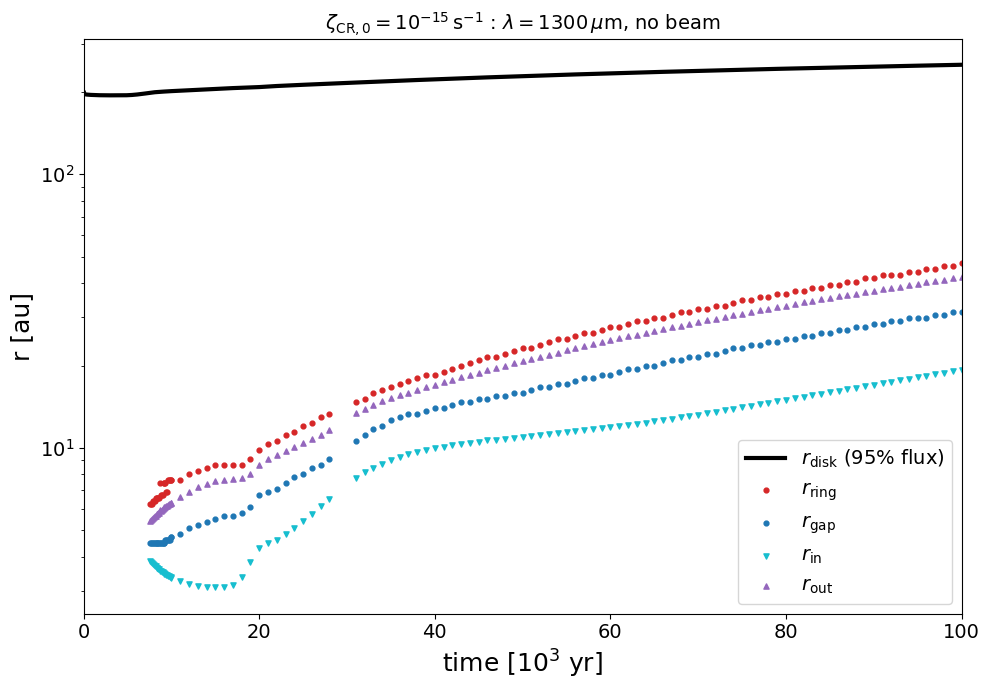

In [3]:
# [旧 cell 45] r_disk, r_ring, r_gap の時間進化
run_nb("gap_detection.ipynb")

fig, ax = plt.subplots(figsize=(10, 7))
ax.plot(t_disk, np.array(r_disk_t) / AU, color="black", lw=3, label=r"$r_{\rm disk}$ (95% flux)")
if len(r_ring_t) > 0:
    ax.scatter(np.array(t_ring) / 1.0e3, np.array(r_ring_t) / AU, s=12, color="tab:red", label=r"$r_{\rm ring}$")
if len(r_gap_t) > 0:
    ax.scatter(np.array(t_gap) / 1.0e3, np.array(r_gap_t) / AU, s=12, color="tab:blue", label=r"$r_{\rm gap}$")
    ax.scatter(np.array(t_gap) / 1.0e3, np.array(r_in_t) / AU, s=14, marker="v", color="tab:cyan", label=r"$r_{\rm in}$")
    ax.scatter(np.array(t_gap) / 1.0e3, np.array(r_out_t) / AU, s=14, marker="^", color="tab:purple", label=r"$r_{\rm out}$")
ax.set_yscale("log")
ax.set_xlim((t_min, t_max))
ax.set_xlabel(r"time [$10^3$ yr]", fontsize=18)
ax.set_ylabel("r [au]", fontsize=18)
ax.set_title(model_names[resultdir] + r" : $\lambda = {:.0f}\,\mu$m".format(Lambda_obs) + beam_label, fontsize=14)
ax.tick_params(labelsize=14)
ax.legend(fontsize=14)
plt.tight_layout()
plt.show()

r shape      = (300,)
sigmad shape = (300, 300)
T shape      = (300,)
Kabs_ shape  = (300,)


/tmp/ipykernel_247905/43710443.py:64: RuntimeWarning: divide by zero encountered in divide


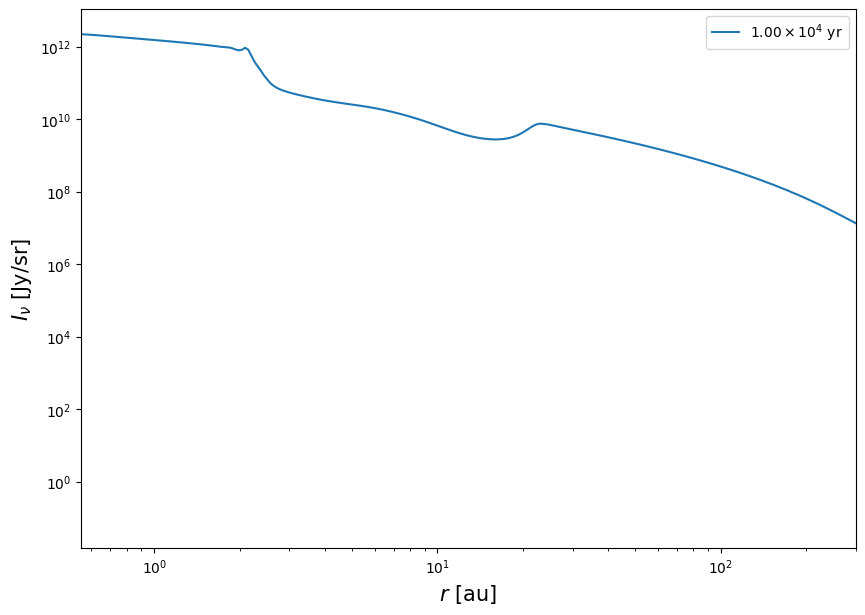

r_ring [au] = [23.23]  r_gap [au] = [15.88]


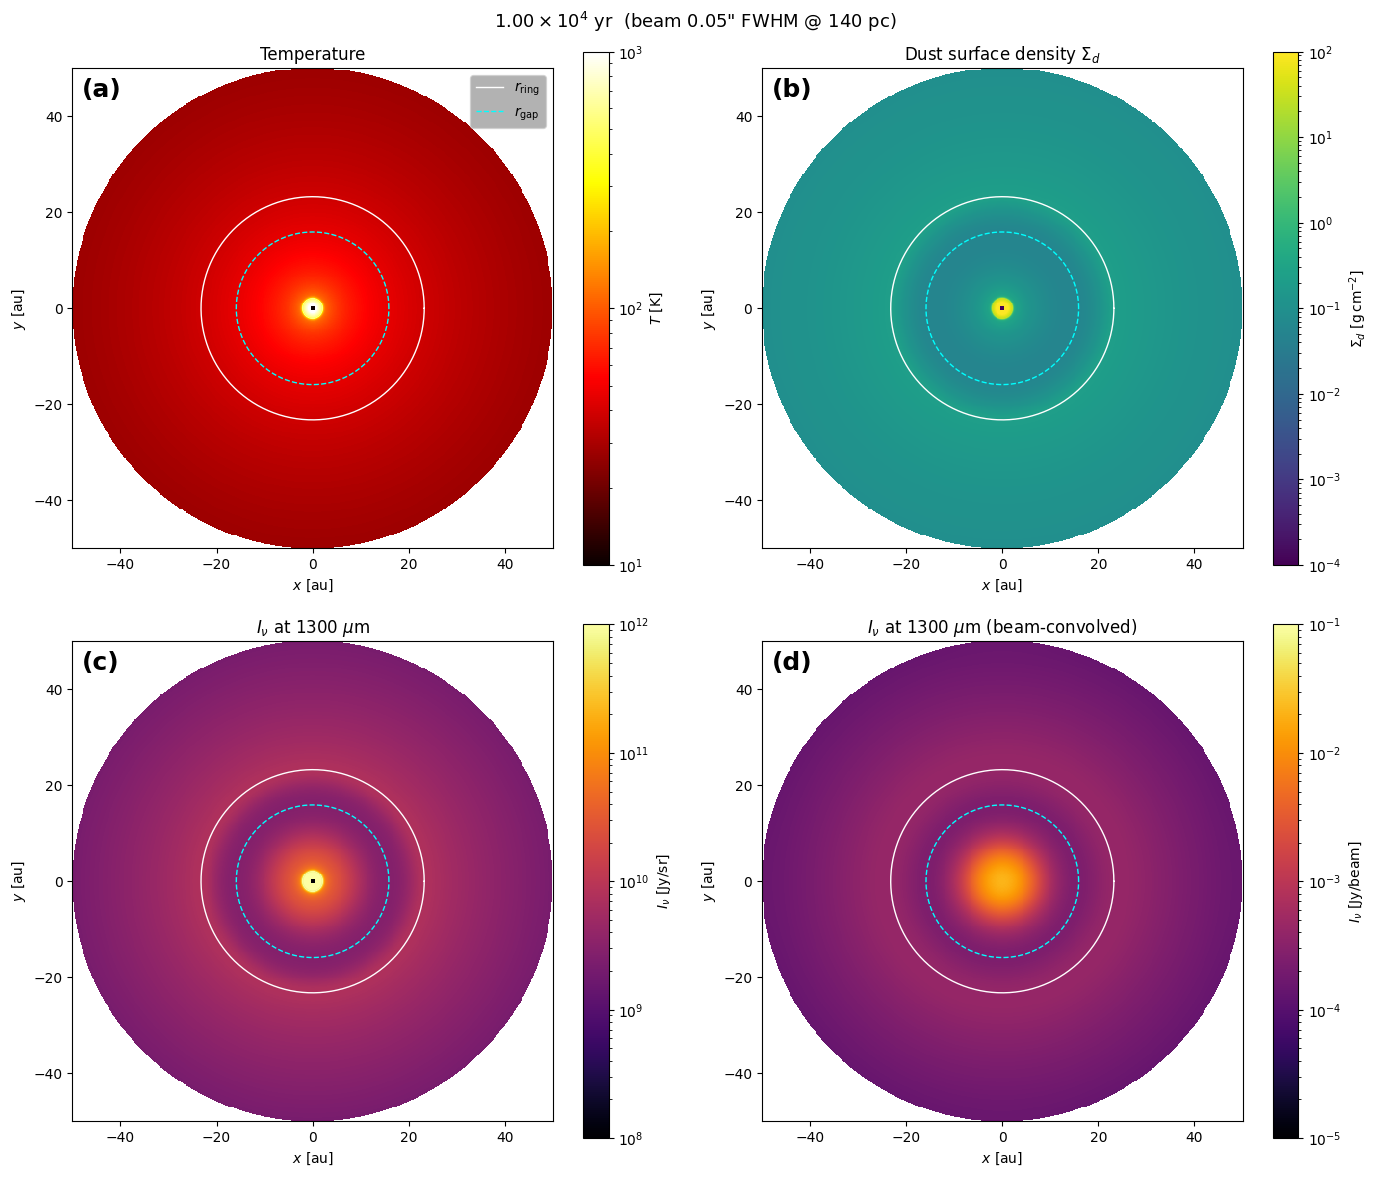

In [4]:
# [旧 cell 46]
os.environ["PATH"] = os.path.expanduser("~/bin") + ":" + os.environ["PATH"]
import sys
sys.modules.pop("optool", None)   # 誤って読み込まれた空のパッケージを捨てる
sys.path.insert(0, "/home/shimokawa/diskcaluation1113/optool")
import optool

# =========================
# 定数
# =========================
AU = 1.495978707e13          # cm
h = 6.62607015e-27           # erg s
light_speed = 2.99792458e10  # cm s^-1
kB = 1.380649e-16            # erg K^-1

Lambda_obs = 1300.0  # micron

# =========================
# ファイル設定
# =========================
outdir = BASE_DIR
resultdir = MODEL
file5_3430 = "/out50000"
file_D5 = outdir + resultdir + file5_3430
file_G5 = file_D5 + "_gas"

files = [
    (file_G5, file_D5, r"$1.00 \times 10^4\ \rm{yr}$")
]

# =========================
# ダストbin情報
# =========================
dmass = np.array([float(i) for i in linecache.getline(file_D5, 1).split()])
dmass_b = np.array([float(i) for i in linecache.getline(file_D5, 2).split()])
dradius = np.array([float(i) for i in linecache.getline(file_D5, 3).split()])
dradius_b = np.array([float(i) for i in linecache.getline(file_D5, 4).split()])
linecache.clearcache()

# =========================
# 吸収係数
# =========================
# ここは手元の既存データに合わせて定義する
# 例:
# Kabs_ = np.ones_like(dradius) * 2.3

Kabs_ = np.asarray(Kabs_, dtype=float)

# =========================
# 関数
# =========================
def Planck_Func(T, lambda_obs_micron):
    T = np.asarray(T, dtype=float)
    L = lambda_obs_micron * 1.0e-4  # micron -> cm
    expo = h * light_speed / (kB * T * L)
    expo = np.clip(expo, None, 700.0)  # overflow防止
    B = 2.0 * h * light_speed**2 / L**5
    B /= (np.exp(expo) - 1.0)
    return B

def Planck_Func_nu(T, lambda_obs_micron):
    T = np.asarray(T, dtype=float)
    L = lambda_obs_micron * 1.0e-4  # micron -> cm
    expo = h * light_speed / (kB * T * L)
    expo = np.clip(expo, None, 700.0)  # overflow防止
    B = 2.0 * h * light_speed**2 / L**5
    B /= (np.exp(expo) - 1.0)
    B *= L**2/light_speed
    return B

def make_1d_intensity(r, sigmad, T, Kabs_, lambda_obs):
    r = np.asarray(r, dtype=float)
    sigmad = np.asarray(sigmad, dtype=float)
    T = np.asarray(T, dtype=float)
    Kabs_ = np.asarray(Kabs_, dtype=float)

    if sigmad.ndim != 2:
        raise ValueError(f"sigmad must be 2D, got {sigmad.shape}")
    if Kabs_.ndim != 1:
        raise ValueError(f"Kabs_ must be 1D, got {Kabs_.shape}")
    if sigmad.shape[0] != Kabs_.shape[0]:
        raise ValueError(
            f"sigmad.shape[0]={sigmad.shape[0]} != Kabs_.shape[0]={Kabs_.shape[0]}"
        )
    if sigmad.shape[1] != T.shape[0]:
        raise ValueError(
            f"sigmad.shape[1]={sigmad.shape[1]} != T.shape[0]={T.shape[0]}"
        )

    tau_abs = np.sum(sigmad * Kabs_[:, None], axis=0)
    #B = Planck_Func(T, lambda_obs)
    B = Planck_Func_nu(T, lambda_obs)
    I_abs = B * (1.0 - np.exp(-tau_abs))*1.0e23 # erg s^{-1} cm^{-2} Hz^{-1} -> Jy/Sr

    return tau_abs, I_abs

def make_2d_from_sigmad_interpolated(
    r, sigmad, T, Kabs_, lambda_obs,
    nxy=500,
    rmax_image=None,
    fill_outer="zero"
):
    r = np.asarray(r, dtype=float)
    sigmad = np.asarray(sigmad, dtype=float)
    T = np.asarray(T, dtype=float)
    Kabs_ = np.asarray(Kabs_, dtype=float)

    if rmax_image is None:
        rmax_image = r[-1]

    x = np.linspace(-rmax_image, rmax_image, nxy)
    y = np.linspace(-rmax_image, rmax_image, nxy)
    X, Y = np.meshgrid(x, y, indexing="xy")
    R = np.sqrt(X**2 + Y**2)

    if fill_outer == "zero":
        T_fill = 0.0
    else:
        T_fill = (T[0], T[-1])

    T_interp = interpolate.interp1d(
        r, T,
        kind="linear",
        bounds_error=False,
        fill_value=T_fill
    )
    T_2d = T_interp(R)

    nbin = sigmad.shape[0]
    sigmad_2d = np.zeros((nbin, nxy, nxy), dtype=float)

    for j in range(nbin):
        if fill_outer == "zero":
            sig_fill = 0.0
        else:
            sig_fill = (sigmad[j, 0], sigmad[j, -1])

        sig_interp = interpolate.interp1d(
            r, sigmad[j],
            kind="linear",
            bounds_error=False,
            fill_value=sig_fill
        )
        sigmad_2d[j] = sig_interp(R)

    tau_2d = np.sum(sigmad_2d * Kabs_[:, None, None], axis=0)
    sigmad_total_2d = np.sum(sigmad_2d, axis=0)
    #B_2d = Planck_Func(T_2d, lambda_obs)
    B_2d = Planck_Func_nu(T_2d, lambda_obs)
    #I_2d = B_2d * (1.0 - np.exp(-tau_2d))
    I_2d = B_2d * (1.0 - np.exp(-tau_2d))*1.0e23 # erg s^{-1} cm^{-2} sr^{-1} Hz^{-1} -> Jy/sr

    return X, Y, tau_2d, I_2d, T_2d, sigmad_total_2d

# =========================
# 設定
# =========================
nxy = 500
rmax_plot_au = 50.0
rmax_plot = rmax_plot_au * AU

# =========================
# ビームパラメータ
# =========================
beam_fwhm_arcsec = 0.05  # ビームFWHM [arcsec]
distance_pc = 140.0       # 距離 [pc]

pixel_size_au = 2.0 * rmax_plot_au / nxy
beam_fwhm_au = beam_fwhm_arcsec * distance_pc   # 1" at d pc = d AU
beam_fwhm_px = beam_fwhm_au / pixel_size_au
sigma_px = beam_fwhm_px / (2.0 * np.sqrt(2.0 * np.log(2.0)))

arcsec_to_rad = np.pi / (180.0 * 3600.0)
Omega_beam = np.pi / (4.0 * np.log(2.0)) * (beam_fwhm_arcsec * arcsec_to_rad)**2  # [sr/beam]

# =========================
# 計算
# =========================
tau_obs = []
I_obs = []
tau2d_obs = []
I2d_obs = []
T2d_obs = []
Sigmad_total2d_obs = []

for (file_G, file_D, time_label) in files:
    data = np.loadtxt(file_D, dtype=float, skiprows=5).T
    data_G = np.loadtxt(file_G, dtype=float).T

    r = np.asarray(data[0], dtype=float)          # (nr,)
    sigmad = np.asarray(data[1:], dtype=float)    # (nbin, nr)
    T = np.asarray(data_G[11, :], dtype=float)    # (nr,)
    T = []
    T = data_G[12,:]
#     for i in range(len(r)):
#         T1 =  2.8e2/np.sqrt(r[i]/AU)
#         T.append(T1)
    T = np.asarray(T, dtype=float)

    sigmad = np.where(np.abs(sigmad) > 1.0e-50, sigmad, 0.0)

    print("r shape      =", r.shape)
    print("sigmad shape =", sigmad.shape)
    print("T shape      =", T.shape)
    print("Kabs_ shape  =", Kabs_.shape)

    # 1D
    tau_abs, I_abs = make_1d_intensity(r, sigmad, T, Kabs_, Lambda_obs)
    tau_obs.append(tau_abs)
    I_obs.append(I_abs)

    # 2D
    X2d, Y2d, tau2d, I2d, T2d, Sigmad_total2d = make_2d_from_sigmad_interpolated(
        r, sigmad, T, Kabs_, Lambda_obs,
        nxy=nxy,
        rmax_image=rmax_plot,
        fill_outer="zero"
    )
    tau2d_obs.append(tau2d)
    I2d_obs.append(I2d)
    T2d_obs.append(T2d)
    Sigmad_total2d_obs.append(Sigmad_total2d)

# =========================
# 1D plot
# =========================
plt.figure(figsize=(10, 7))
plt.xlabel(r"$r\ [{\rm au}]$", fontsize=15)
plt.ylabel(r"$I_{\nu} \ [\mathrm{Jy/sr}]$", fontsize=15)
plt.xscale("log")
plt.yscale("log")
plt.xlim(r_min, r_max)
# plt.ylim(1.0e-6, 1.0e0)
plt.plot(r / AU, I_obs[0], label=files[0][2])
plt.legend()
plt.show()

# =========================
# 4パネル 2D plot
# =========================
mask = (X2d**2 + Y2d**2) <= rmax_plot**2

# ビーム畳み込み → Jy/beam
I2d_conv = gaussian_filter(I2d_obs[0], sigma=sigma_px)
I2d_jy_beam = I2d_conv * Omega_beam

fig, axes = plt.subplots(2, 2, figsize=(14, 12))

def add_panel(ax, data, title, clabel, norm, cmap="inferno"):
    d = np.where(mask, data, np.nan)
    pcm = ax.pcolormesh(X2d / AU, Y2d / AU, d,
                        shading="auto", norm=norm, cmap=cmap)
    ax.set_xlabel(r"$x\ [{\rm au}]$")
    ax.set_ylabel(r"$y\ [{\rm au}]$")
    ax.set_xlim(-rmax_plot_au, rmax_plot_au)
    ax.set_ylim(-rmax_plot_au, rmax_plot_au)
    ax.set_aspect("equal")
    ax.set_title(title)
    cbar = fig.colorbar(pcm, ax=ax)
    cbar.set_label(clabel)

# パネル1: 温度
add_panel(axes[0, 0],
          np.clip(T2d_obs[0], 1.0, None),
          "Temperature",
          r"$T\ [\mathrm{K}]$",
          norm=LogNorm(vmin=10, vmax=1000), cmap="hot")

# パネル2: ダスト面密度
add_panel(axes[0, 1],
          np.clip(Sigmad_total2d_obs[0], 1.0e-10, None),
          r"Dust surface density $\Sigma_d$",
          r"$\Sigma_d\ [\mathrm{g\,cm^{-2}}]$",
          norm=LogNorm(vmin=1.0e-4, vmax=1.0e2), cmap="viridis")

# パネル3: I_nu [Jy/sr]
add_panel(axes[1, 0],
          np.clip(I2d_obs[0], 1.0e-20, None),
          r"$I_\nu$ at 1300 $\mu$m",
          r"$I_\nu\ [\mathrm{Jy/sr}]$",
          norm=LogNorm(vmin=1.0e8, vmax=1.0e12), cmap="inferno")

# パネル4: I_nu [Jy/beam]
add_panel(axes[1, 1],
          np.clip(I2d_jy_beam, 1.0e-30, None),
          r"$I_\nu$ at 1300 $\mu$m (beam-convolved)",
          r"$I_\nu\ [\mathrm{Jy/beam}]$",
          norm=LogNorm(vmin=1.0e-5, vmax=1.0e-1), cmap="inferno")

# r_ring (白実線), r_gap (シアン破線) を円で表示 -- 上のセル (r_disk/r_ring/r_gap) の結果 t_ring, r_ring_t, t_gap, r_gap_t を使う
t_map = int(file5_3430.lstrip("/out"))
rings_map = [rr / AU for tt, rr in zip(t_ring, r_ring_t) if tt == t_map]
gaps_map = [rg / AU for tt, rg in zip(t_gap, r_gap_t) if tt == t_map]
if t_map not in t_ring + t_gap:
    print(f"WARNING: t = {t_map} yr の r_ring / r_gap が上のセルの結果にありません")
theta = np.linspace(0.0, 2.0 * np.pi, 360)
for ax in axes.flat:
    for rr in rings_map:
        if rr <= rmax_plot_au:
            ax.plot(rr * np.cos(theta), rr * np.sin(theta), color="white", lw=1.0, ls="-")
    for rg in gaps_map:
        if rg <= rmax_plot_au:
            ax.plot(rg * np.cos(theta), rg * np.sin(theta), color="cyan", lw=1.0, ls="--")
axes[0, 0].legend(handles=[Line2D([0], [0], color="white", lw=1.0, ls="-", label=r"$r_{\rm ring}$"),
                           Line2D([0], [0], color="cyan", lw=1.0, ls="--", label=r"$r_{\rm gap}$")],
                  loc="upper right", fontsize=10, facecolor="gray", framealpha=0.6)
print("r_ring [au] =", np.round(rings_map, 2), " r_gap [au] =", np.round(gaps_map, 2))

plt.suptitle(files[0][2] + f'  (beam {beam_fwhm_arcsec}" FWHM @ {distance_pc:.0f} pc)', fontsize=13)
plt.tight_layout()
# plt.savefig(fig_path("25e3yr_I_850.png", root=ANALYSIS_FIG_DIR))
plt.show()

C18O  : r_ring = [2.56]  r_gap = [2.15] [au]
dust  : r_ring = [29.92]  r_gap = [20.46] [au]
凍結境界 (T = 20 K) = 98.44 au


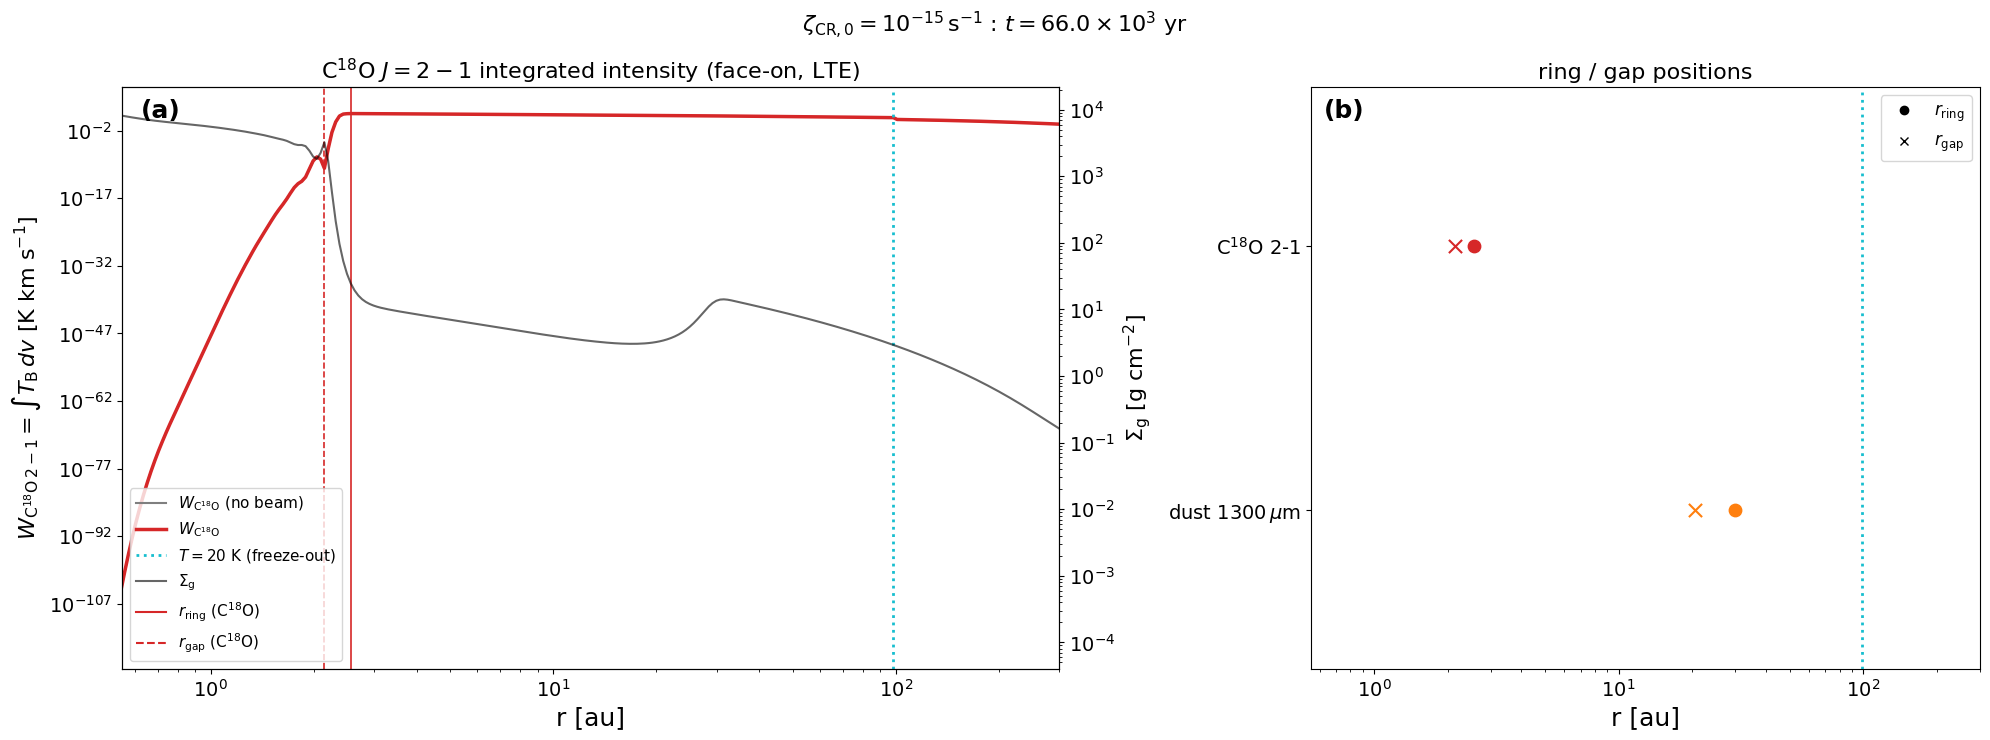

C18O 2-1 の線中心の光学的厚さ tau_line (min, median, max) = [  0.     27.462 338.585]


In [5]:
# [旧 cell 47]
# ======================================================
# C18O J=2-1 擬似観測によるガスのリング・ギャップの同定 (正面向き, LTE, 鉛直等温)
#
# 方針は Aso & Machida (2020, arXiv:2011.01478, "Testing Disk Identification Methods Through
# Numerical Simulations of Protostellar Evolution") Sec. 2.2 に倣う:
#   - 化学計算は行わず, C18O の存在量は H2 に対して X(C18O) = 5e-7 (T > 20 K) とし,
#     T < 20 K では CO 同位体のダスト表面への凍結を表すため 2 桁下げる (X = 5e-9)
#     (X の値は Lacy et al. 1994; Wilson & Rood 1994 を引用している)
#   - 温度はシミュレーションのガス温度をそのまま使う (ここでは中心面温度 T, out_gas 12 列)
#   - 線と連続波 (ダスト) の両方の吸収を含め, 連続波を差し引いた線放射を見る
# Aso & Machida は RADMC-3D を使うが, ここでは鉛直方向に等温を仮定するので
# 正面向きの視線上で源関数が一定となり, 輻射輸送は厳密に解ける:
#   I_line,v = B_nu(T) [exp(-tau_d) - exp(-(tau_d + tau_v))]        (連続波差し引き後)
#   tau_d = sum_j Sigma_d,j kappa_abs,j(nu0)   (kappa_abs は上の強度プロファイルのセルと同じく optool -dsharp で
#                                               各ダストビンごとに計算 -> ダストのサイズ分布をすべて反映)
#   tau_v = (c^3 / (8 pi nu0^3)) A_ul N_u (exp(h nu0/kT) - 1) phi_v ,  phi_v = exp(-v^2/2s^2) / (sqrt(2 pi) s)
#           (LTE の光学的厚さ: Mangum & Shirley 2015, PASP 127, 266)
#   N_u = N(C18O) g_u exp(-E_u/kT) / Q(T) ,  Q(T) ~ kT/(h B0) + 1/3 (線形回転子: Mangum & Shirley 2015)
#   N(C18O) = X(T) Sigma_g / (mu_H2 m_H) ,  mu_H2 = 2.8 (H2 1分子あたりの平均質量: Kauffmann et al. 2008, A&A 487, 993)
#   s = sqrt(kT/m_C18O + v_turb^2) : 正面向きなのでケプラー回転は視線速度を持たず, 熱的(+乱流)幅のみ
# 分子データ (C18O): nu0 = 219.5603541 GHz (Aso & Machida 2020), A_ul(2-1) = 6.011e-7 s^-1, g_u = 5,
#   E_u/k = 15.81 K (LAMDA: Schoier et al. 2005, A&A 432, 369), B0 = 54891.420 MHz (CDMS: Muller et al. 2005)
# 積分強度 W(r) = int T_B dv [K km/s] (Rayleigh-Jeans の輝度温度 T_B = c^2 I / (2 k nu0^2)).
# use_beam = True なら上の強度プロファイルのセルと同じガウスビーム (行列 W) で畳み込み,
# 同じ find_radii で r_ring, r_gap を求めて, 同じ時刻のダスト連続波 (Lambda_obs) の r_ring, r_gap と比べる.
# 上の強度プロファイルのセルの path, years, Kabs_, find_radii, Planck_Func_nu, sigmag_ini, use_beam, r_u, W,
# beam_fwhm_au を使う (このセルではそれらを上書きしない)
# 注意: 鉛直等温なので T_mid < 20 K の半径では柱全体が凍結扱いになり, W が 1/100 に落ちる (見かけの縁).
# ======================================================

t_c18o = 66000                 # 擬似観測する時刻 [yr] (上のセルの years に含まれること)
X_c18o_warm = 5.0e-7           # X(C18O) (T > T_freeze)        : Aso & Machida (2020)
X_c18o_drop = 1.0e-2           # T < T_freeze での存在量の倍率 : Aso & Machida (2020)
T_freeze = 20.0                # 凍結温度 [K]                  : Aso & Machida (2020)
v_turb = 0.0                   # 非熱的な速度分散 [cm/s] (0: 熱的幅のみ)
nu0_c18o = 219.5603541e9       # [Hz]
A_ul_c18o = 6.011e-7           # [s^-1]
g_u_c18o = 5.0
E_u_c18o = 15.81               # [K]
B0_c18o = 54891.420e6          # [Hz]
mu_H2 = 2.8
m_H_c18o = 1.6735575e-24       # [g]
m_c18o = 30.0 * 1.66053907e-24 # C18O 分子の質量 [g]
lambda_c18o = light_speed / nu0_c18o * 1.0e4   # [micron] (= 1365.4 micron)

if t_c18o not in years:
    raise ValueError(f"t = {t_c18o} yr は上の強度プロファイルのセルの years にありません")

# ---- kappa_abs(nu0) : 各ダストビン, optool -dsharp (上の強度プロファイルのセルと同じ) ----
dradius_c18o = np.array([float(i) for i in linecache.getline(path + "/out{}".format(t_c18o), 3).split()])
linecache.clearcache()
Kabs_c18o = []
for a in dradius_c18o:
    cmd = "optool -dsharp -a {0} {0} -l {1} -print kabs".format(a * 1.0e4, lambda_c18o)
    out = subprocess.run(cmd, shell=True, capture_output=True, text=True).stdout
    Kabs_c18o.append(float(out.strip().split()[-1]))
Kabs_c18o = np.array(Kabs_c18o)

# ---- 読み込み ----
d_c18o = np.loadtxt(path + "/out{}".format(t_c18o), skiprows=5)
gas_c18o = np.loadtxt(path + "/out{}_gas".format(t_c18o), usecols=(1, 12))
r_c = d_c18o[:, 0]
sigd_c = np.where(np.abs(d_c18o[:, 1:]) > 1.0e-50, d_c18o[:, 1:], 0.0)
sigmag_c, T_c = gas_c18o[:, 0], gas_c18o[:, 1]

# ---- C18O 2-1 の積分強度 W(r) ----
X_c = np.where(T_c > T_freeze, X_c18o_warm, X_c18o_warm * X_c18o_drop)
N_c18o = X_c * sigmag_c / (mu_H2 * m_H_c18o)                          # [cm^-2]
Q_c = kB * T_c / (h * B0_c18o) + 1.0 / 3.0
N_u = N_c18o * g_u_c18o * np.exp(-E_u_c18o / T_c) / Q_c
s_v = np.sqrt(kB * T_c / m_c18o + v_turb**2)                          # [cm/s]
tau0_v = light_speed**3 / (8.0 * np.pi * nu0_c18o**3) * A_ul_c18o * N_u * np.expm1(h * nu0_c18o / (kB * T_c))  # x phi_v
tau_d_c = sigd_c @ Kabs_c18o
B_c = Planck_Func_nu(T_c, lambda_c18o)                                # [erg s^-1 cm^-2 Hz^-1 sr^-1]

u = np.linspace(-6.0, 6.0, 481)                                       # v / s_v
phi_u = np.exp(-0.5 * u**2) / np.sqrt(2.0 * np.pi)                    # phi_v * s_v
tau_line = (tau0_v / s_v)[:, None] * phi_u[None, :]                   # (nr, nv)
I_line = B_c[:, None] * (np.exp(-tau_d_c)[:, None] - np.exp(-(tau_d_c[:, None] + tau_line)))
TB_line = light_speed**2 * I_line / (2.0 * kB * nu0_c18o**2)          # [K]
W_c18o = np.trapezoid(TB_line, u, axis=1) * s_v / 1.0e5                   # [K km/s]
tau_line_peak = tau0_v / (np.sqrt(2.0 * np.pi) * s_v)

# 凍結境界: T が T_freeze を横切る最も外側の半径
k = np.where((T_c[:-1] - T_freeze) * (T_c[1:] - T_freeze) <= 0.0)[0]
r_freeze = r_c[k[-1]] / AU if len(k) > 0 else np.nan

# ---- ビーム畳み込みとリング・ギャップの同定 (C18O / ダスト連続波) ----
I_dust_c = Planck_Func_nu(T_c, Lambda_obs) * (1.0 - np.exp(-(sigd_c @ Kabs_))) * 1.0e23   # Jy/sr (上のセルと同じ)
ratio_c = sigmag_c / sigmag_ini
if use_beam:
    r_prof = r_u
    W_prof = W @ np.interp(r_u, r_c, W_c18o, left=0.0, right=0.0)
    I_prof = W @ np.interp(r_u, r_c, I_dust_c, left=0.0, right=0.0)
    ratio_prof = np.interp(r_u, r_c, ratio_c)
else:
    r_prof, W_prof, I_prof, ratio_prof = r_c, W_c18o, I_dust_c, ratio_c
_, rings_gas, gaps_gas, _, _, _ = find_radii(r_prof, W_prof, ratio_prof)
_, rings_dust, gaps_dust, _, _, _ = find_radii(r_prof, I_prof, ratio_prof)
print("C18O  : r_ring =", np.round(np.array(rings_gas) / AU, 2), " r_gap =", np.round(np.array(gaps_gas) / AU, 2), "[au]")
print("dust  : r_ring =", np.round(np.array(rings_dust) / AU, 2), " r_gap =", np.round(np.array(gaps_dust) / AU, 2), "[au]")
print("凍結境界 (T = {:.0f} K) = {:.2f} au".format(T_freeze, r_freeze))

# ---- 図 ----
fig, (ax_W, ax_cmp) = plt.subplots(1, 2, figsize=(20, 7.5), gridspec_kw={"width_ratios": [1.4, 1.0]})

ax_W.plot(r_c / AU, W_c18o, color="tab:gray", lw=1.5, label=r"$W_{\rm C^{18}O}$ (no beam)")
ax_W.plot(r_prof / AU, W_prof, color="tab:red", lw=2.5,
          label=r"$W_{\rm C^{18}O}$" + (" (beam {:.0f} au)".format(beam_fwhm_au) if use_beam else ""))
for x in rings_gas:
    ax_W.axvline(x / AU, color="tab:red", lw=1.2, ls="-")
for x in gaps_gas:
    ax_W.axvline(x / AU, color="tab:red", lw=1.2, ls="--")
ax_W.axvline(r_freeze, color="tab:cyan", lw=2, ls=":", label=r"$T = {:.0f}$ K (freeze-out)".format(T_freeze))
ax_W.set_xscale("log"); ax_W.set_yscale("log")
ax_W.set_xlim((r_min, r_max))
ax_W.set_xlabel("r [au]", fontsize=18)
ax_W.set_ylabel(r"$W_{\rm C^{18}O\,2-1} = \int T_{\rm B}\,dv$ [K km s$^{-1}$]", fontsize=16)
ax_S = ax_W.twinx()
ax_S.plot(r_c / AU, sigmag_c, color="black", lw=1.5, alpha=0.6, label=r"$\Sigma_{\rm g}$")
ax_S.set_yscale("log")
ax_S.set_ylabel(r"$\Sigma_{\rm g}$ [g cm$^{-2}$]", fontsize=16)
h1, l1 = ax_W.get_legend_handles_labels()
h2, l2 = ax_S.get_legend_handles_labels()
ax_W.legend(h1 + h2 + [Line2D([], [], color="tab:red", ls="-"), Line2D([], [], color="tab:red", ls="--")],
            l1 + l2 + [r"$r_{\rm ring}$ (C$^{18}$O)", r"$r_{\rm gap}$ (C$^{18}$O)"], fontsize=11, loc="lower left")
ax_W.set_title(r"C$^{18}$O $J=2-1$ integrated intensity (face-on, LTE)", fontsize=16)

for y, (rings, gaps, col) in enumerate([(rings_dust, gaps_dust, "tab:orange"), (rings_gas, gaps_gas, "tab:red")]):
    ax_cmp.scatter(np.array(rings) / AU, np.full(len(rings), y), s=80, marker="o", color=col)
    ax_cmp.scatter(np.array(gaps) / AU, np.full(len(gaps), y), s=90, marker="x", color=col)
ax_cmp.axvline(r_freeze, color="tab:cyan", lw=2, ls=":")
ax_cmp.set_yticks([0, 1])
ax_cmp.set_yticklabels([r"dust ${:.0f}\,\mu$m".format(Lambda_obs), r"C$^{18}$O 2-1"], fontsize=14)
ax_cmp.set_ylim(-0.6, 1.6)
ax_cmp.set_xscale("log")
ax_cmp.set_xlim((r_min, r_max))
ax_cmp.set_xlabel("r [au]", fontsize=18)
ax_cmp.legend(handles=[Line2D([], [], color="black", lw=0, marker="o", label=r"$r_{\rm ring}$"),
                       Line2D([], [], color="black", lw=0, marker="x", label=r"$r_{\rm gap}$")], fontsize=12, loc="upper right")
ax_cmp.set_title("ring / gap positions", fontsize=16)
for ax in (ax_W, ax_S, ax_cmp):
    ax.tick_params(labelsize=14)

model_key = path[len(outdir):]
fig.suptitle(model_names.get(model_key, model_key) + r" : $t = {:.1f} \times 10^3$ yr".format(t_c18o / 1.0e3), fontsize=16)
plt.tight_layout()
plt.show()
print("C18O 2-1 の線中心の光学的厚さ tau_line (min, median, max) =",
      np.round([tau_line_peak.min(), np.median(tau_line_peak), tau_line_peak.max()], 3))

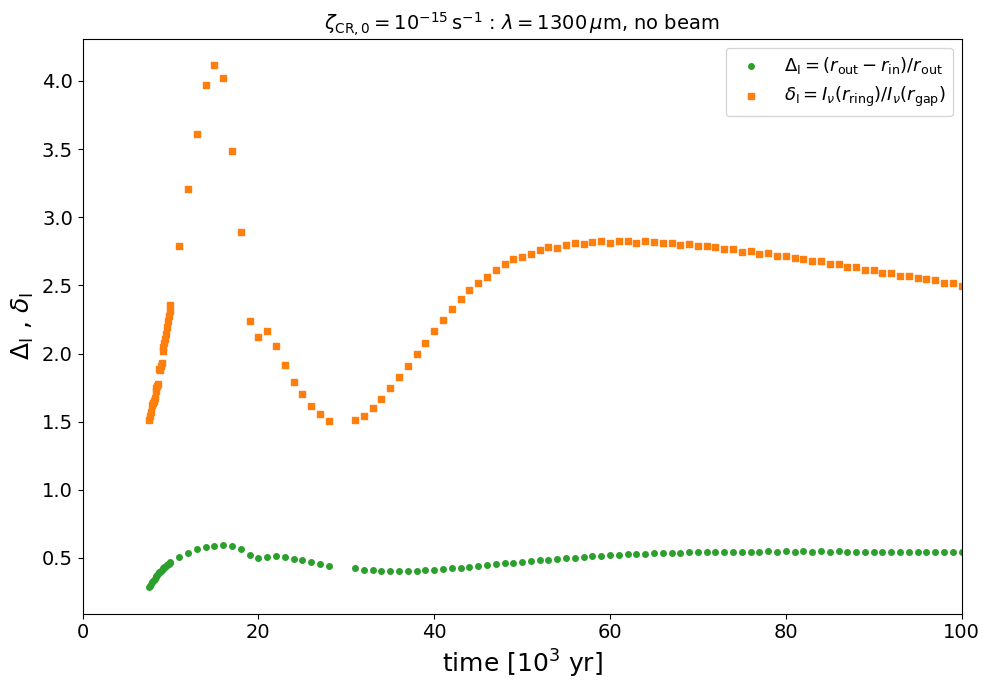

In [6]:
# [旧 cell 48]
# ======================================================
# ギャップの幅 Delta_I と深さ delta_I の時間進化 (Yamaguchi et al. 2024 Eq. 9, 10)
#   Delta_I = (r_out - r_in) / r_out ,  delta_I = I(r_ring) / I(r_gap)
# 上のセル (r_disk, r_ring, r_gap, r_in, r_out) の結果 t_gap, r_in_t, r_out_t, delta_I_t を使う
# どちらも無次元なので同じ図に描く (r_in, r_out が求まらない時刻の Delta_I は描かない)
# ======================================================
t_gap_kyr = np.array(t_gap) / 1.0e3
Delta_I = (np.array(r_out_t) - np.array(r_in_t)) / np.array(r_out_t)
delta_I = np.array(delta_I_t)

fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(t_gap_kyr, Delta_I, s=16, color="tab:green", label=r"$\Delta_{\rm I} = (r_{\rm out}-r_{\rm in})/r_{\rm out}$")
ax.scatter(t_gap_kyr, delta_I, s=16, marker="s", color="tab:orange", label=r"$\delta_{\rm I} = I_\nu(r_{\rm ring})/I_\nu(r_{\rm gap})$")
# ax.axhline(0.5, color="gray", lw=1.5, linestyle="dashed", label=r"$\Delta_{\rm I} = 0.5$ (narrow / wide gap)")
# ax.set_yscale("log")
# ax.set_xlim(left=0.0)
ax.set_xlim((t_min, t_max))
ax.set_xlabel(r"time [$10^3$ yr]", fontsize=18)
ax.set_ylabel(r"$\Delta_{\rm I}$ , $\delta_{\rm I}$", fontsize=18)
ax.set_title(model_names[resultdir] + r" : $\lambda = {:.0f}\,\mu$m".format(Lambda_obs) + beam_label, fontsize=14)
ax.tick_params(labelsize=14)
ax.legend(fontsize=13)
plt.tight_layout()
plt.show()

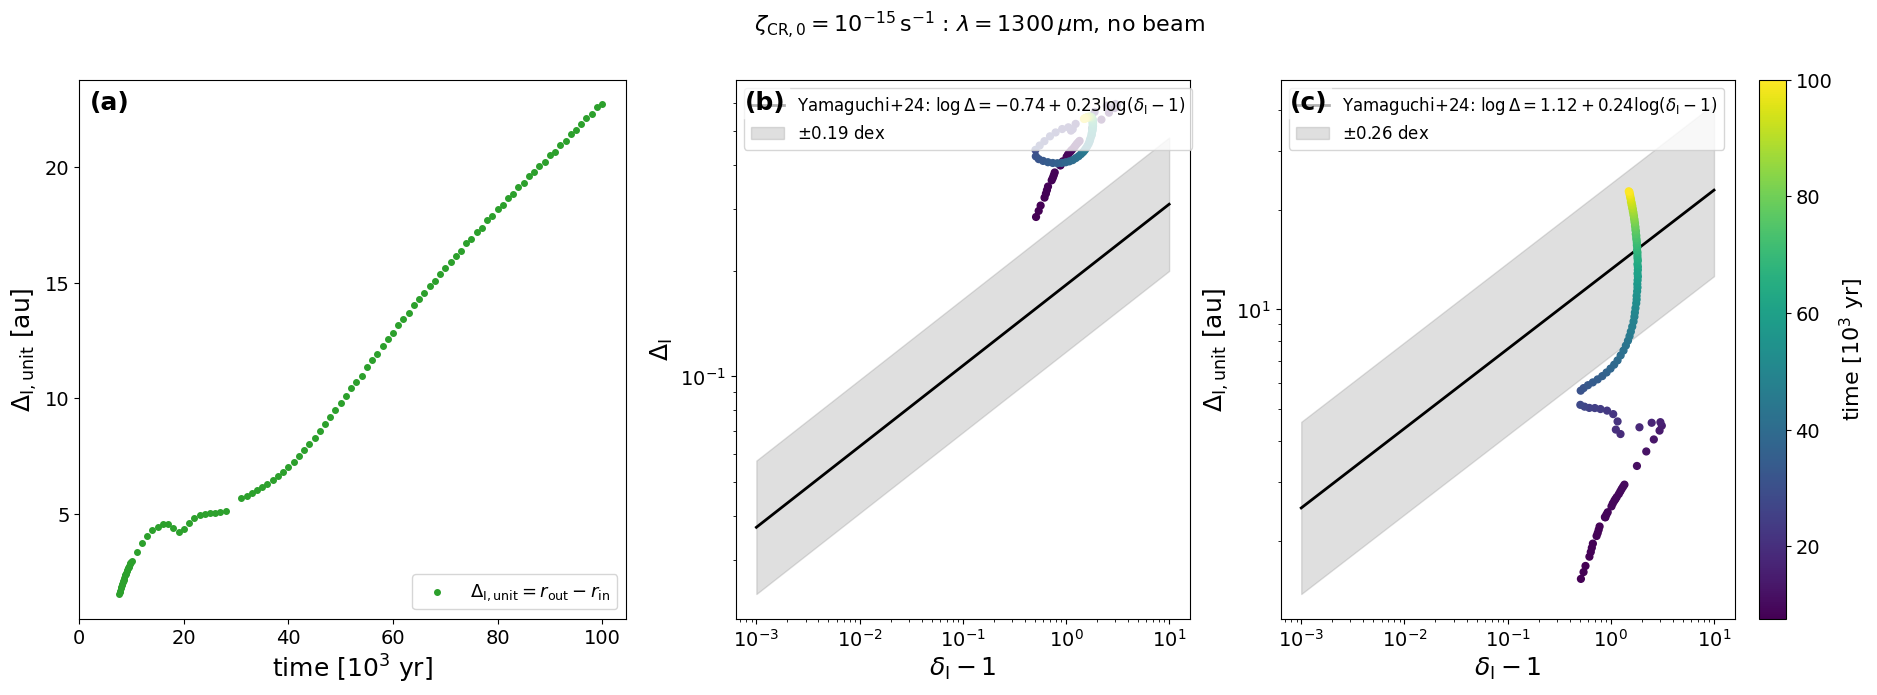

In [7]:
# [旧 cell 49]
# ======================================================
# (左) ギャップ幅 Delta_I,unit = r_out - r_in [au] の時間進化 (ビーム FWHM を参考に表示)
# (中, 右) 幅-深さ関係 Delta vs delta_I - 1 と Yamaguchi et al. (2024) Sec. 8.4 の回帰
#   log Delta = A + B log(delta_I - 1) , r_ring > 30 au のギャップでの結果:
#     Delta_I      : A = -0.74, B = 0.23, sigma = 0.19 dex
#     Delta_I,unit : A =  1.12, B = 0.24, sigma = 0.26 dex  (au)
# 上の 2 セル (r_disk/r_ring/r_gap, Delta_I/delta_I) の結果を使う
# ======================================================
paper_fits = {"Delta_I": (-0.74, 0.23, 0.19), "Delta_I_unit": (1.12, 0.24, 0.26)}

width_au = (np.array(r_out_t) - np.array(r_in_t)) / AU
ok = np.isfinite(Delta_I) & (delta_I > 1.0)
x_fit = np.logspace(-3, 1, 100)

fig, axes = plt.subplots(1, 3, figsize=(24, 7))

ax = axes[0]
ax.scatter(t_gap_kyr, width_au, s=16, color="tab:green", label=r"$\Delta_{\rm I,unit} = r_{\rm out} - r_{\rm in}$")
if use_beam:
    ax.axhline(beam_fwhm_au, color="gray", lw=1.5, linestyle="dashed", label="beam FWHM ({:.0f} au)".format(beam_fwhm_au))
ax.set_xlim(left=0.0)
ax.set_xlabel(r"time [$10^3$ yr]", fontsize=18)
ax.set_ylabel(r"$\Delta_{\rm I,unit}$ [au]", fontsize=18)
ax.legend(fontsize=13)

for ax, (y, key, ylabel) in zip(axes[1:], [(Delta_I, "Delta_I", r"$\Delta_{\rm I}$"),
                                           (width_au, "Delta_I_unit", r"$\Delta_{\rm I,unit}$ [au]")]):
    A, B, sig = paper_fits[key]
    y_fit = 10.0**(A + B * np.log10(x_fit))
    ax.plot(x_fit, y_fit, color="black", lw=2, label=r"Yamaguchi+24: $\log\Delta = {:.2f} + {:.2f}\log(\delta_{{\rm I}}-1)$".format(A, B))
    ax.fill_between(x_fit, y_fit * 10.0**-sig, y_fit * 10.0**sig, color="gray", alpha=0.25, label=r"$\pm{:.2f}$ dex".format(sig))
    sc = ax.scatter(delta_I[ok] - 1.0, y[ok], c=t_gap_kyr[ok], cmap="viridis", s=24, zorder=3)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(r"$\delta_{\rm I} - 1$", fontsize=18)
    ax.set_ylabel(ylabel, fontsize=18)
    ax.legend(fontsize=12, loc="upper left")
cb = fig.colorbar(sc, ax=axes[1:], pad=0.02)
cb.set_label(r"time [$10^3$ yr]", fontsize=16)
cb.ax.tick_params(labelsize=14)

for ax in axes:
    ax.tick_params(labelsize=14)
fig.suptitle(model_names[resultdir] + r" : $\lambda = {:.0f}\,\mu$m".format(Lambda_obs) + beam_label, fontsize=16)
plt.show()

基準ギャップ : t_open = 7600 yr, r_gap(t_open) = 4.47 au, P = 9.5 yr
t_ref = t_open + 1000 orbit = 17065 yr  (出力の最終時刻 100000 yr)

t_ref 直前の出力 t = 17000 yr でのギャップ:
 gap   t_open[yr]    r_gap[au]    Delta_I    delta_I
   0         7600         5.62      0.589      3.488


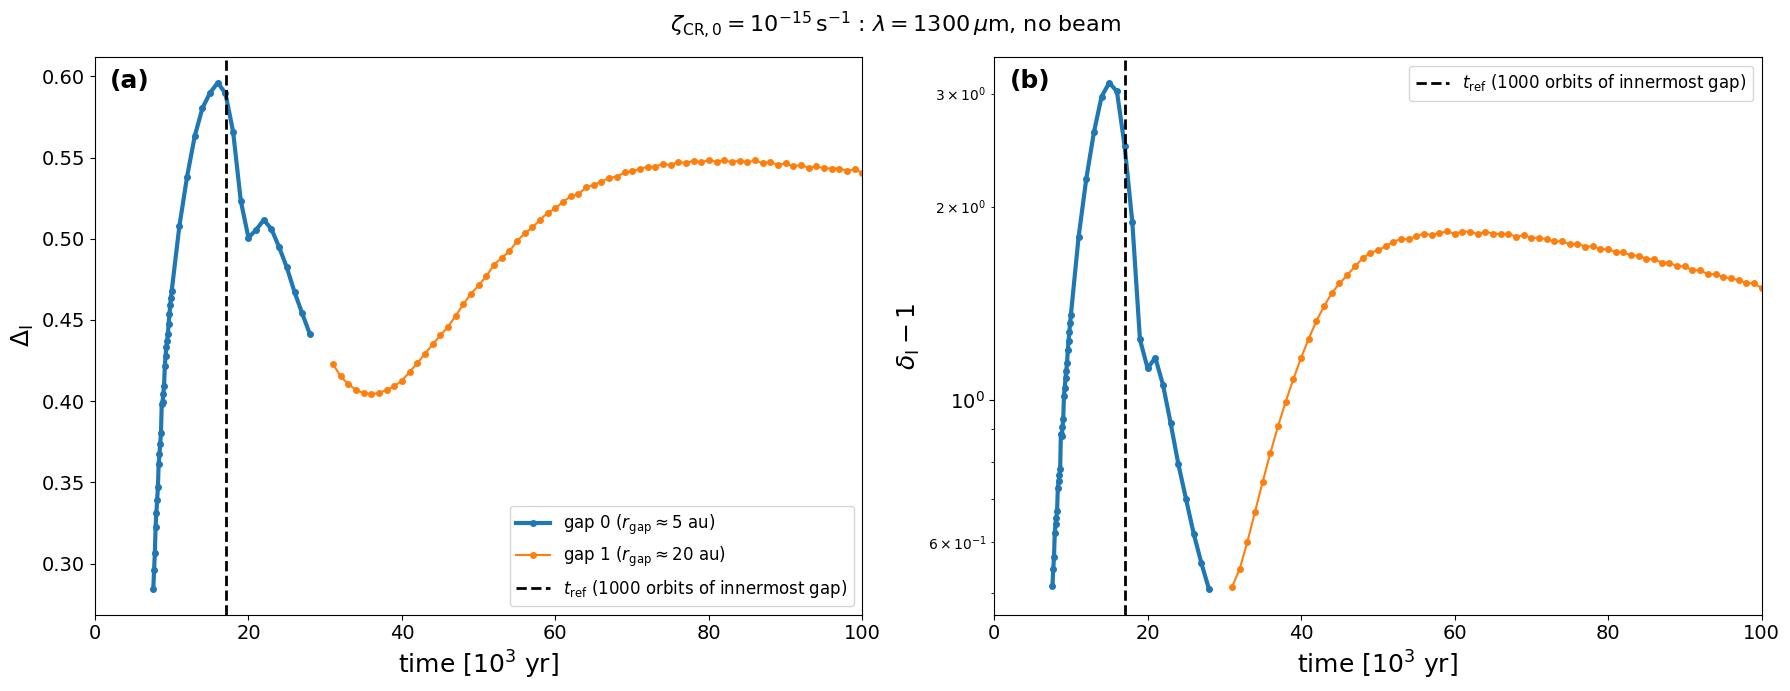

In [8]:
# [旧 cell 52]
# ======================================================
# 一番内側のギャップが開いてから N_orb orbit 後を基準時刻 t_ref とし, その時刻での各ギャップの Delta_I, delta_I (後処理)
# 上のセル (r_disk/r_ring/r_gap, Delta_I/delta_I) の結果 t_disk, t_gap, r_gap_t, Delta_I, delta_I を使う
# 1. 各時刻のギャップを r_gap の近さで時間方向につなぎ, ギャップごとの時系列 (トラック) を作る
#      |ln(r_gap / r_gap,前回)| < match_tol かつ 前回の検出から max_miss スナップショット以内なら同じギャップ
# 2. 基準ギャップ : t_open (最初に検出された時刻) での r_gap が最小のトラック (r_gap > r_ref_min のものから選ぶ)
# 3. t_ref = t_open,in + N_orb P(r_gap,in(t_open)) ,  P = 2 pi / Omega
#      integrate_orbits = True なら orbit 数を N(t) = int_{t_open}^t dt'/P(r_gap,in(t')) で数え, N = N_orb となる時刻
# ======================================================

G = 6.67408e-08
Msolar = 1.989000e+33
yr = 3.155760e+07

N_orb = 1000.0            # 基準とする orbit 数
integrate_orbits = False  # True: r_gap の移動を考慮して orbit 数を積分
r_ref_min = 0.0           # 基準ギャップに選ぶ r_gap の下限 [au] (内境界付近の見かけのギャップを除く)
match_tol = 0.15          # 同じギャップとみなす |ln(r_gap/r_gap,前回)| の上限
max_miss = 3              # 検出が途切れてもつなぐスナップショット数
min_points = 10           # これより点数の少ないトラックは除外

def P_orb(r):
    return 2.0 * np.pi / np.sqrt(G * Msolar / r**3) / yr   # [yr]

# ---- 1. トラッキング ----
t_gap_arr, r_gap_arr = np.array(t_gap, dtype=float), np.array(r_gap_t)
t_snap = np.array(sorted(set(t_gap)), dtype=float)
tracks = []   # 各要素: {"idx": [t_gap 配列の index], "last_r": , "last_k": スナップショット番号}
for k, ts in enumerate(t_snap):
    used = set()
    for j in np.where(t_gap_arr == ts)[0]:
        best, best_d = None, match_tol
        for n, tr in enumerate(tracks):
            if n in used or k - tr["last_k"] > max_miss:
                continue
            d = abs(np.log(r_gap_arr[j] / tr["last_r"]))
            if d < best_d:
                best, best_d = n, d
        if best is None:
            tracks.append({"idx": [], "last_r": None, "last_k": None})
            best = len(tracks) - 1
        tracks[best]["idx"].append(j)
        tracks[best]["last_r"], tracks[best]["last_k"] = r_gap_arr[j], k
        used.add(best)
tracks = [np.array(tr["idx"]) for tr in tracks if len(tr["idx"]) >= min_points]
tracks.sort(key=lambda idx: r_gap_arr[idx[0]])   # t_open での r_gap の小さい順

# ---- 2, 3. 基準ギャップと t_ref ----
t_end = t_disk[-1] * 1.0e3   # 出力の最終時刻 [yr]
cand = [idx for idx in tracks if r_gap_arr[idx[0]] / AU > r_ref_min]
if len(cand) == 0:
    raise RuntimeError("基準にできるギャップがありません")
idx_in = cand[0]
t_in, rg_in = t_gap_arr[idx_in], r_gap_arr[idx_in]
t_open_in = t_in[0]
if integrate_orbits:
    N_t = np.concatenate(([0.0], np.cumsum(0.5 * (1.0 / P_orb(rg_in[1:]) + 1.0 / P_orb(rg_in[:-1])) * np.diff(t_in))))
    t_ref = np.interp(N_orb, N_t, t_in) if N_t[-1] >= N_orb else np.nan
    N_now = N_t[-1]
else:
    t_ref = t_open_in + N_orb * P_orb(rg_in[0])
    N_now = (t_end - t_open_in) / P_orb(rg_in[0])
reached = np.isfinite(t_ref) and t_ref <= t_end

print("基準ギャップ : t_open = {:.0f} yr, r_gap(t_open) = {:.2f} au, P = {:.1f} yr".format(
    t_open_in, rg_in[0] / AU, P_orb(rg_in[0])))
if reached:
    print("t_ref = t_open + {:.0f} orbit = {:.0f} yr  (出力の最終時刻 {:.0f} yr)".format(N_orb, t_ref, t_end))
else:
    t_need = "" if integrate_orbits else " (t_ref = {:.0f} yr)".format(t_ref)
    print("未到達 : 最終時刻 {:.0f} yr で {:.0f} orbit / {:.0f} orbit{}".format(t_end, N_now, N_orb, t_need))

# t_ref 以前で最も近いスナップショットでの各ギャップ
t_eval = t_snap[t_snap <= (t_ref if reached else t_end)][-1]
print("\n{} t = {:.0f} yr でのギャップ:".format("t_ref 直前の出力" if reached else "最終出力 (参考)", t_eval))
print("{:>4} {:>12} {:>12} {:>10} {:>10}".format("gap", "t_open[yr]", "r_gap[au]", "Delta_I", "delta_I"))
for n, idx in enumerate(tracks):
    j = idx[t_gap_arr[idx] == t_eval]
    if len(j) == 0:
        continue
    j = j[0]
    print("{:>4} {:>12.0f} {:>12.2f} {:>10.3f} {:>10.3f}".format(
        n, t_gap_arr[idx[0]], r_gap_arr[j] / AU, Delta_I[j], delta_I[j]))

# ---- 図: Delta_I, delta_I - 1 の時系列 + t_ref ----
fig, axes = plt.subplots(1, 2, figsize=(18, 7), sharex=True)
for n, idx in enumerate(tracks):
    col = "C{}".format(n % 10)
    tk = t_gap_arr[idx] / 1.0e3
    lab = r"gap {} ($r_{{\rm gap}} \approx {:.0f}$ au)".format(n, np.median(r_gap_arr[idx]) / AU)
    lw = 3 if idx is idx_in else 1.5
    axes[0].plot(tk, Delta_I[idx], "o-", ms=4, lw=lw, color=col, label=lab)
    axes[1].plot(tk, delta_I[idx] - 1.0, "o-", ms=4, lw=lw, color=col)
if reached:
    for ax in axes:
        ax.axvline(t_ref / 1.0e3, color="black", lw=2, linestyle="dashed",
                   label=r"$t_{{\rm ref}}$ ({:.0f} orbits of innermost gap)".format(N_orb))
axes[1].set_yscale("log")
axes[0].set_xlim((t_min, t_max))
axes[1].set_xlim((t_min, t_max))
axes[0].set_ylabel(r"$\Delta_{\rm I}$", fontsize=18)
axes[1].set_ylabel(r"$\delta_{\rm I} - 1$", fontsize=18)
for ax in axes:
    ax.set_xlabel(r"time [$10^3$ yr]", fontsize=18)
    ax.tick_params(labelsize=14)
axes[0].legend(fontsize=12)
if reached:
    axes[1].legend(fontsize=12)
fig.suptitle(model_names[resultdir] + r" : $\lambda = {:.0f}\,\mu$m".format(Lambda_obs) + beam_label, fontsize=16)
plt.tight_layout()
plt.show()

## ガスとダストのリング・ギャップ

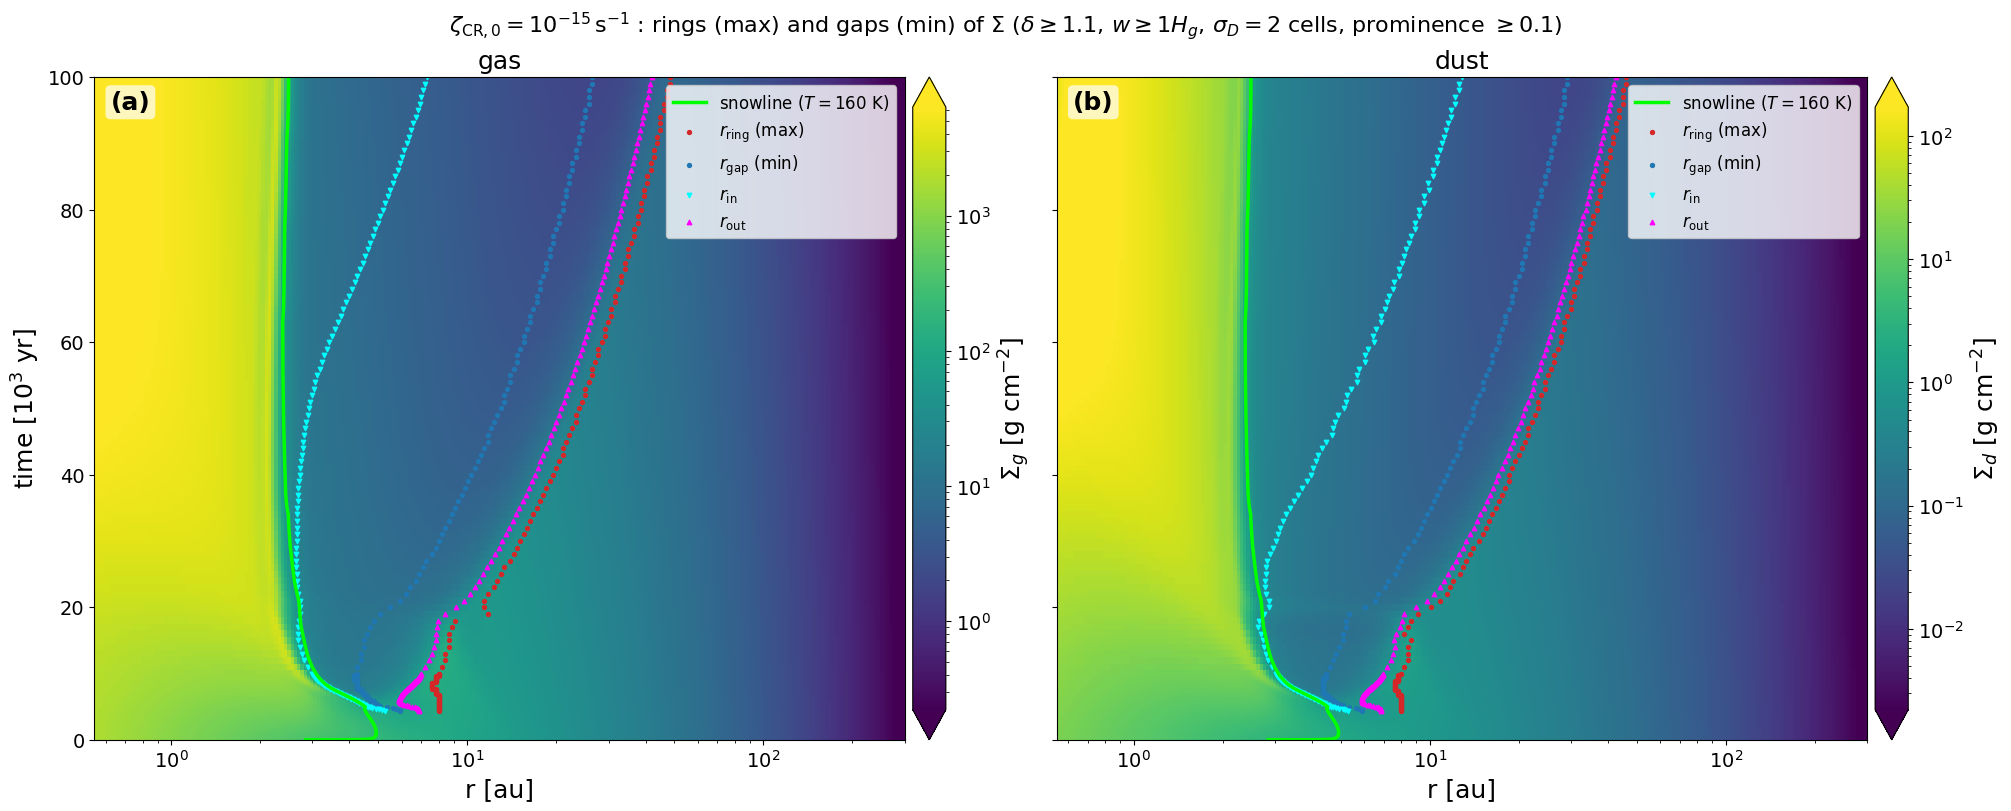

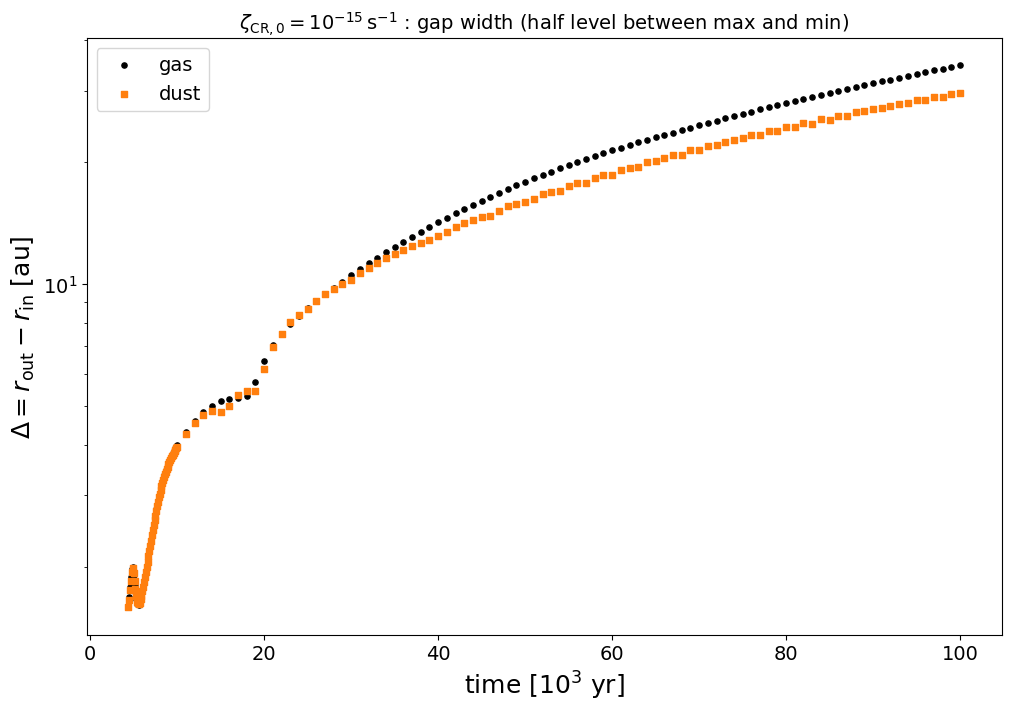

In [9]:
# [旧 cell 71]
# ======================================================
# ガス Sigma_g とダスト Sigma_d (全ビンの和) のリング・ギャップと幅の (r,t) 時空図 (1x2 ミニマップ) + 幅の時間進化
# 判定は cell 45 (強度 I_nu, Yamaguchi et al. 2024) と同じ方法を Sigma に適用する:
#   r_ring : d ln Sigma/dr = 0 の極大 , r_gap : 極小. 各 r_gap はその外側で最初の r_ring と組にする
#   D = d ln Sigma/dr にはガウシアンフィルター (sigma = D_SIGMA セル) をかけ, その符号変化で極値を探す
#   (log 格子なので 1 セル = 一定の d ln r). 極値の位置は符号変化の前後 +-D_SIGMA セルで生の Sigma が最大/最小のセル
#   深さ・縁は生の Sigma から求める
#   use_prominence = True なら, 符号変化の代わりに scipy.signal.find_peaks を平滑化した ln Sigma (極大) と
#   -ln Sigma (極小) にかけ, prominence (周りからの落ち込みの深さ, ln Sigma で) >= prom_min の極値だけを使う
#   (ギャップの prominence は両側の極大のうち低い方からの深さ). 各ギャップは外側で最も近いリングと組にする
#   採用条件 (揺らぎ除去): 深さ Sigma(r_ring)/Sigma(r_gap) >= sig_delta_min ,  r_ring - r_gap >= sig_w_min_H * H_g(r_gap)
#                          (H_g = c_s/Omega) , r_det_min <= r <= r_max の範囲のみで判定 (図は r_min から描く.
#                          内側の無関係な構造を除くため判定の内端 r_det_min を図の内端 r_min と別にする. 図に灰色破線で表示)
# ギャップの縁: Sigma_edge = 0.5 (Sigma(r_ring) + Sigma(r_gap))  (Case 1)
#   r_out : r_gap < r < r_ring で Sigma = Sigma_edge となる最大の r
#   r_in  : r_peak <= r < r_gap で Sigma = Sigma_edge となる最小の r (r_peak はギャップのすぐ内側の極大, なければ範囲の内端)
#   Sigma(r_peak) < Sigma_edge なら Sigma_edge = 0.5 (Sigma(r_peak) + Sigma(r_gap))  (Case 2)
#   幅 Delta = r_out - r_in
# 図1: 色は Sigma_g, Sigma_d (LogNorm). r_ring (赤), r_gap (青), r_in (シアン), r_out (紫) とスノーライン (T = T_snow)
# 図2: ガスとダストの幅 Delta = r_out - r_in の時間進化 (ギャップが複数ある時刻はすべて描く)
# 判定の関数 (find_ring_gap など) と条件 (r_det_min, sig_delta_min, sig_w_min_H, D_SIGMA, use_prominence, prom_min) は thesis_common.ipynb
# file 列: out (5行目以降) 0:r_cen 1~:Sigma_d,j     out_gas 1:Sigma_g 12:T
# ======================================================
AU = 1.495979e+13
G = 6.67408e-08
Msolar = 1.989000e+33
kB = 1.38064852e-16
mH = 1.67353e-24
mu = 2.34

outdir = BASE_DIR
resultdir = MODEL
t_start = 0
sig_range_g = None             # Sigma_g のカラーバーの範囲 [g cm^-2]. None なら 1-99 パーセンタイル
sig_range_d = None             # Sigma_d のカラーバーの範囲 [g cm^-2]. None なら 1-99 パーセンタイル

path = outdir + resultdir
years = sorted(int(m.group(1)) for f in os.listdir(path)
               if (m := re.fullmatch(r"out(\d+)_gas", f)) and int(m.group(1)) >= t_start
               and os.path.exists(path + "/out{}".format(m.group(1))))

M_star = Msolar
with open(path + "/input") as f:
    for line in f:
        if line.split("//")[0].split("=")[0].strip() == "star_mass":
            M_star = float(line.split("//")[0].split("=")[1]) * Msolar

res = {key: {"t": [], "ring": [], "gap": [], "in": [], "out": []} for key in ("gas", "dust")}
maps = {"gas": [], "dust": []}
r_snow = []
for year in years:
    d = np.loadtxt(path + "/out{}".format(year), skiprows=5)
    gas = np.loadtxt(path + "/out{}_gas".format(year), usecols=(1, 12))
    sigmag, T = gas[:, 0], gas[:, 1]
    r = d[:, 0]
    sigmad = np.where(np.abs(d[:, 1:]) > 1.0e-50, d[:, 1:], 0.0).sum(axis=1)
    Hg = np.sqrt(kB * T / (mu * mH)) / np.sqrt(G * M_star / r**3)
    sel = (r >= r_det_min * AU) & (r <= r_max * AU)
    for key, S in (("gas", sigmag), ("dust", sigmad)):
        maps[key].append(S)
        rings, gaps, e_in, e_out = find_ring_gap(r[sel], S[sel], Hg[sel])
        res[key]["t"] += [year / 1.0e3] * len(gaps)
        res[key]["ring"] += rings
        res[key]["gap"] += gaps
        res[key]["in"] += e_in
        res[key]["out"] += e_out

    r_snow.append(find_snowline(r, T))

for key in res:
    res[key] = {q: np.array(v) for q, v in res[key].items()}
    res[key]["width"] = res[key]["out"] - res[key]["in"]
maps = {key: np.array(v) for key, v in maps.items()}
t = np.array(years) / 1.0e3
r_au = r / AU
sel = (r_au >= r_min) & (r_au <= r_max)

# ---- 図1: Sigma_g, Sigma_d の時空図とリング・ギャップ ----
fig, axes = plt.subplots(1, 2, figsize=(20, 8), sharey=True, layout="constrained")
for ax, key, srange, clabel in zip(axes, ("gas", "dust"), (sig_range_g, sig_range_d),
                                   (r"$\Sigma_g$ [g cm$^{-2}$]", r"$\Sigma_d$ [g cm$^{-2}$]")):
    v = maps[key][:, sel]
    if srange is None:
        srange = tuple(np.nanpercentile(v[v > 0.0], [1, 99]))
    ax.set_facecolor("lightgray")
    pc = ax.pcolormesh(r_au, t, np.where(maps[key] > 0.0, maps[key], np.nan), cmap="viridis",
                       norm=LogNorm(vmin=srange[0], vmax=srange[1]), shading="nearest", rasterized=True)
    cb = fig.colorbar(pc, ax=ax, extend="both", pad=0.01)
    cb.set_label(clabel, fontsize=18)
    cb.ax.tick_params(labelsize=14)
    rs = res[key]
    ax.plot(r_snow, t, color="lime", lw=2.5, label=r"snowline ($T = {:.0f}$ K)".format(T_snow))
    # ax.axvline(r_det_min, color="gray", lw=2.0, ls="dashed", label=r"$r_{\rm det,min}$")
    ax.scatter(rs["ring"] / AU, rs["t"], s=8, color="tab:red", label=r"$r_{\rm ring}$ (max)")
    ax.scatter(rs["gap"] / AU, rs["t"], s=8, color="tab:blue", label=r"$r_{\rm gap}$ (min)")
    ax.scatter(rs["in"] / AU, rs["t"], s=10, marker="v", color="cyan", label=r"$r_{\rm in}$")
    ax.scatter(rs["out"] / AU, rs["t"], s=10, marker="^", color="magenta", label=r"$r_{\rm out}$")
    ax.set_xscale("log")
    ax.set_xlim((r_min, r_max))
    ax.set_ylim((t[0], t[-1]))
    ax.set_xlabel("r [au]", fontsize=18)
    ax.set_title(key, fontsize=18)
    ax.tick_params(labelsize=14)
    ax.legend(fontsize=12, loc="upper right")
axes[0].set_ylabel(r"time [$10^3$ yr]", fontsize=18)
fig.suptitle(model_names[resultdir] + r" : rings (max) and gaps (min) of $\Sigma$ ($\delta \geq %g$, $w \geq %g H_g$, $\sigma_D = %g$ cells%s)"
             % (sig_delta_min, sig_w_min_H, D_SIGMA, r", prominence $\geq %g$" % prom_min if use_prominence else ""), fontsize=16)
plt.show()

# ---- 図2: 幅 Delta = r_out - r_in の時間進化 ----
fig, ax = plt.subplots(figsize=(10, 7), layout="constrained")
ax.scatter(res["gas"]["t"], res["gas"]["width"] / AU, s=14, color="black", label="gas")
ax.scatter(res["dust"]["t"], res["dust"]["width"] / AU, s=14, marker="s", color="tab:orange", label="dust")
ax.set_yscale("log")
ax.set_xlabel(r"time [$10^3$ yr]", fontsize=18)
ax.set_ylabel(r"$\Delta = r_{\rm out} - r_{\rm in}$ [au]", fontsize=18)
ax.set_title(model_names[resultdir] + " : gap width (half level between max and min)", fontsize=14)
ax.tick_params(labelsize=14)
ax.legend(fontsize=14)
plt.show()

In [10]:
# [旧 cell 62, 64, 72]
# ======================================================
# ギャップの縁 [r_in, r_out] の時間進化. 冒頭の GAP_EDGE で選ぶ (以降の Phi_gap, 冪指数のセルで使う)
#   "wind" : r_in = スノーライン (T = T_snow となる最も外側の半径),
#            r_out = r_in より外側 (r <= r_search_max) で F_net = F_adv + F_diff が符号を変える最も外側の半径
#   "gas"  : 旧 cell 71 の Sigma_g の half-level の縁. "wind" の [r_in, r_out] に r_gap が入るギャップのうち, 中点に最も近いもの
#   "dust" : 旧 cell 71 の Sigma_d の half-level の縁 (選び方は "gas" と同じ)
# 旧 cell 71 を先に実行すること
# file_gas 列: 0:r_cen 1:sigmag 4:vg_r 12:T     file_mag 列: 2:B_z 3:etaO_R 4:etaA_R
# ======================================================

if GAP_EDGE not in ("wind", "gas", "dust"):
    raise ValueError("GAP_EDGE = {} は選べません".format(GAP_EDGE))

outdir = BASE_DIR
resultdir = MODEL
t_start = 0
use_eta_cap = True    # eta_tot を eta_max (input) で上限 (コードと同じ)

path_gas = outdir + resultdir
path_mag = outdir + resultdir + "_B"
years = list_years(path_gas, t_start, path_mag=path_mag)
M_star, eta_max = read_input(path_gas)

def select_gap(key, year, r0, r1):
    # 旧 cell 71 の key ("gas"/"dust") のギャップから, 時刻 year で [r0, r1] に入るものを選ぶ (番号, なければ None)
    rs = res[key]
    j = np.where((np.round(rs["t"] * 1.0e3).astype(int) == year) & (rs["gap"] >= r0) & (rs["gap"] <= r1)
                 & np.isfinite(rs["in"]) & np.isfinite(rs["out"]))[0]
    if len(j) == 0:
        return None
    return j[np.argmin(np.abs(rs["gap"][j] - 0.5 * (r0 + r1)))]

r_in_t, r_out_t, r_in_w_t, r_out_w_t = [], [], [], []
for year in years:
    r, sig, vgr, T = np.loadtxt(path_gas + "/out{}_gas".format(year), usecols=(0, 1, 4, 12)).T
    B, etaO, etaA = np.loadtxt(path_mag + "/out{}_B".format(year), usecols=(2, 3, 4)).T
    eta = np.minimum(etaO + etaA, eta_max) if use_eta_cap else etaO + etaA
    r_in, r_out = find_wind_edges(r, T, sig, vgr, B, eta)
    r_in_w_t.append(r_in)
    r_out_w_t.append(r_out)
    if GAP_EDGE != "wind":
        j = select_gap(GAP_EDGE, year, r_in, r_out) if np.isfinite(r_out) else None
        r_in, r_out = (res[GAP_EDGE]["in"][j], res[GAP_EDGE]["out"][j]) if j is not None else (np.nan, np.nan)
    r_in_t.append(r_in)
    r_out_t.append(r_out)

t_kyr = np.array(years) / 1.0e3
r_in_t = np.array(r_in_t)
r_out_t = np.array(r_out_t)
r_in_w_t = np.array(r_in_w_t)      # F_net = 0 の判定の縁 (GAP_EDGE によらない)
r_out_w_t = np.array(r_out_w_t)


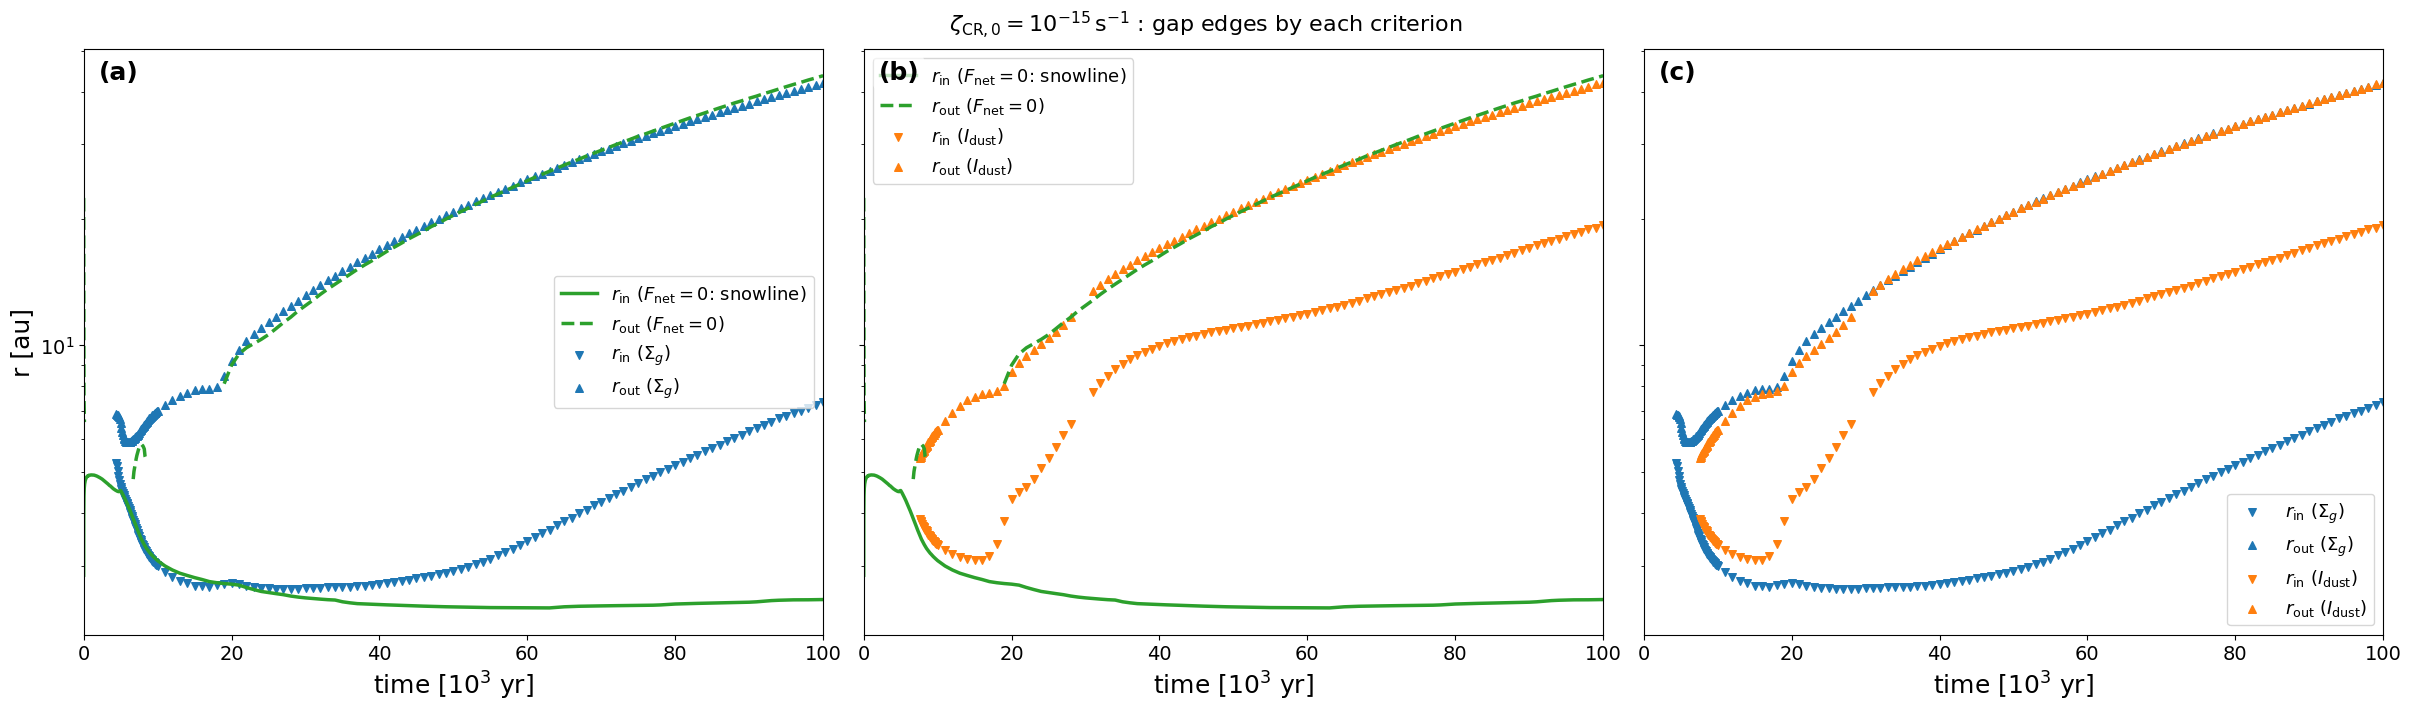

In [11]:
# ======================================================
# 判定ごとのギャップの縁 r_in, r_out の時間進化の比較 (1x3)
#   (左) Sigma_g と F_net = 0    (中) I_dust と F_net = 0    (右) Sigma_g と I_dust
#   F_net = 0 : r_in = スノーライン, r_out = F_net が符号を変える最も外側の半径 (各時刻に 1 つなので線で描く. 求まらない時刻は空白)
#   Sigma_g, I_dust : 検出したギャップをすべて描く (F_net の範囲で絞らない. 同じ時刻に複数あれば点も複数)
# 上のセルの res (Sigma_g), res_I (I_dust: gap_detection.ipynb), t_kyr, r_in_w_t, r_out_w_t を使う -> 先に実行すること
# ======================================================

crit_styles = {"Sigma_g": ("tab:blue", r"$\Sigma_g$", res["gas"]), "I_dust": ("tab:orange", r"$I_{\rm dust}$", res_I)}
color_F = "tab:green"

fig, axes = plt.subplots(1, 3, figsize=(24, 7), sharey=True, layout="constrained")
for ax, keys, with_F in zip(axes, (("Sigma_g",), ("I_dust",), ("Sigma_g", "I_dust")), (True, True, False)):
    if with_F:
        ax.plot(t_kyr, r_in_w_t / AU, color=color_F, lw=2.5, label=r"$r_{\rm in}$ ($F_{\rm net} = 0$: snowline)")
        ax.plot(t_kyr, r_out_w_t / AU, color=color_F, lw=2.5, ls="dashed", label=r"$r_{\rm out}$ ($F_{\rm net} = 0$)")
    for key in keys:
        color, label, rs = crit_styles[key]
        ax.scatter(rs["t"], rs["in"] / AU, s=30, marker="v", color=color, label=r"$r_{\rm in}$ (%s)" % label)
        ax.scatter(rs["t"], rs["out"] / AU, s=30, marker="^", color=color, label=r"$r_{\rm out}$ (%s)" % label)
    ax.set_yscale("log")
    ax.set_xlim(t_kyr[0], t_kyr[-1])
    ax.set_xlabel(r"time [$10^3$ yr]", fontsize=18)
    ax.tick_params(labelsize=14)
    ax.legend(fontsize=13)
axes[0].set_ylabel("r [au]", fontsize=18)
fig.suptitle(model_names[resultdir] + " : gap edges by each criterion", fontsize=16)
plt.show()


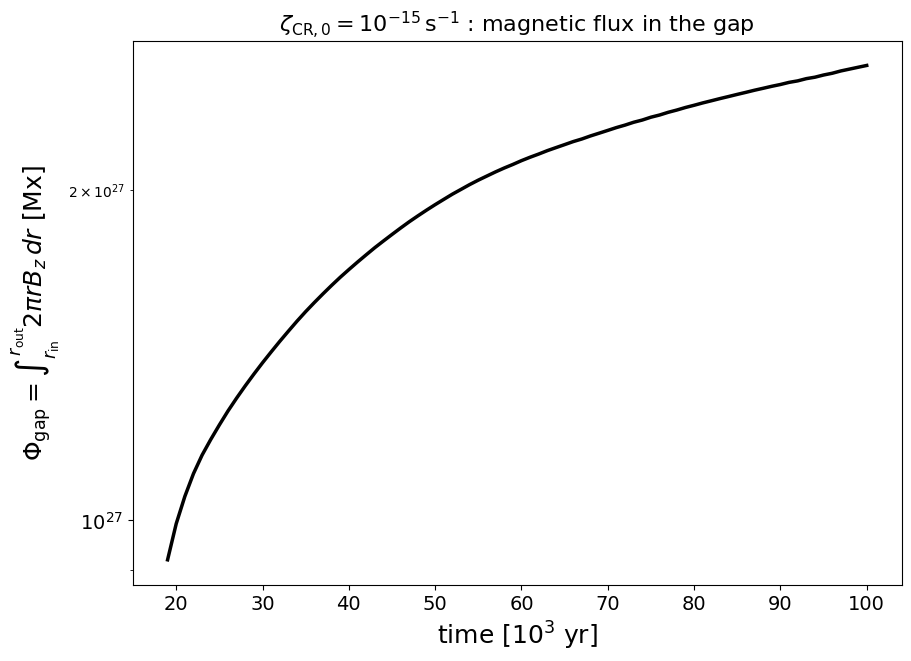

In [ ]:
# [旧 cell 70]
# ======================================================
# ギャップ内の総磁束 Phi_gap(t) = int_{r_in}^{r_out} 2 pi r B_z dr の時間進化
# cell 62 の years, path_gas, path_mag, r_in_t, r_out_t, t_kyr, model_names, resultdir を使う
#   -> cell 62 を先に実行すること
# r_in, r_out は時刻ごとに動くので, Phi_gap の変化には境界の移動の寄与も含まれる
# file_mag 列: 2:B_z
# t >= t_gap_min のギャップが求まった時刻のみ使う (初期の過渡的な符号変化を除く)
# ======================================================

# t_gap_min (これより前の時刻は使わない [kyr]) は thesis_common.ipynb で設定する

use = np.isfinite(r_in_t) & np.isfinite(r_out_t) & (t_kyr >= t_gap_min)
Phi_gap = np.full(len(years), np.nan)
for n, year in enumerate(years):
    if not use[n]:
        continue
    r = np.loadtxt(path_gas + "/out{}_gas".format(year), usecols=(0,))
    B = np.loadtxt(path_mag + "/out{}_B".format(year), usecols=(2,))
    r0, r1 = r_in_t[n], r_out_t[n]
    rr = np.concatenate(([r0], r[(r > r0) & (r < r1)], [r1]))
    Phi_gap[n] = np.trapezoid(2.0 * np.pi * rr * np.interp(rr, r, B), rr)

fig, ax = plt.subplots(figsize=(9, 6.5), layout="constrained")
ax.plot(t_kyr[use], Phi_gap[use], color="black", lw=2.5)
ax.set_yscale("log")
ax.set_xlabel(r"time [$10^3$ yr]", fontsize=18)
ax.set_ylabel(r"$\Phi_{\rm gap} = \int_{r_{\rm in}}^{r_{\rm out}} 2\pi r B_z\,dr$ [Mx]", fontsize=18)
ax.tick_params(labelsize=14)
ax.set_title(model_names[resultdir] + " : magnetic flux in the gap", fontsize=16)
plt.show()

/tmp/ipykernel_247905/2984517981.py:49: RuntimeWarning: divide by zero encountered in divide
  return r, {"sig": sig, "B": B, "C": eta / (r * v), "Rm": cs2 / (eta * omega), "flux": 2.0 * np.pi * r * B, "v": v,


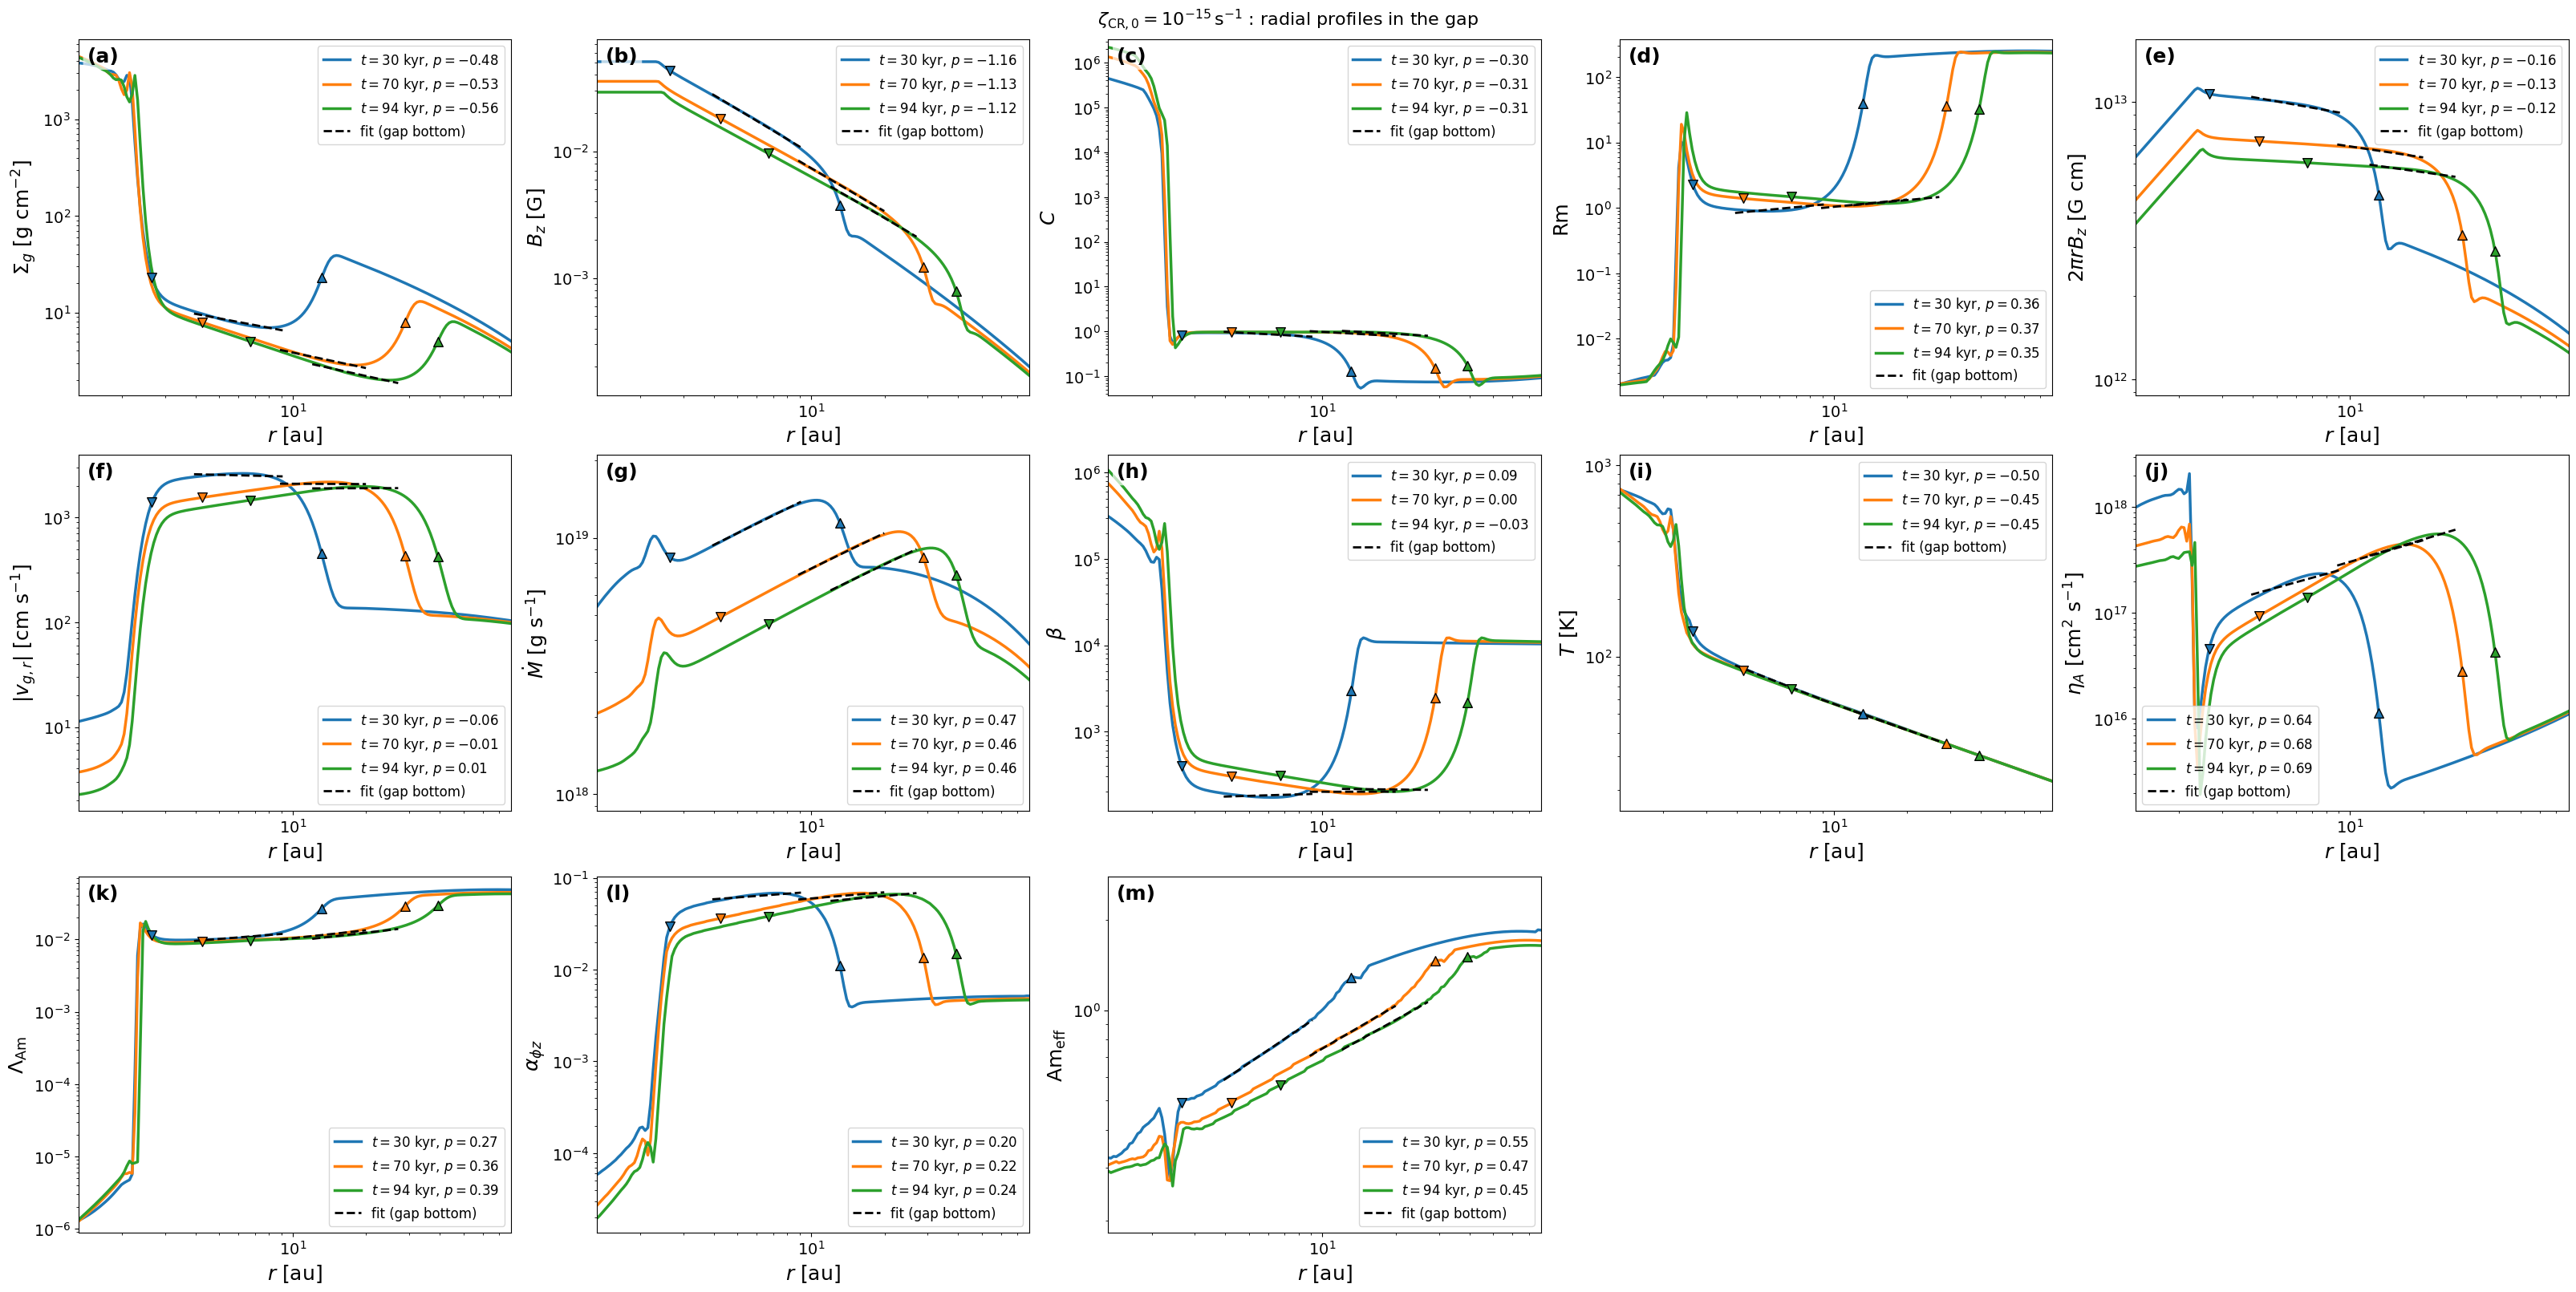

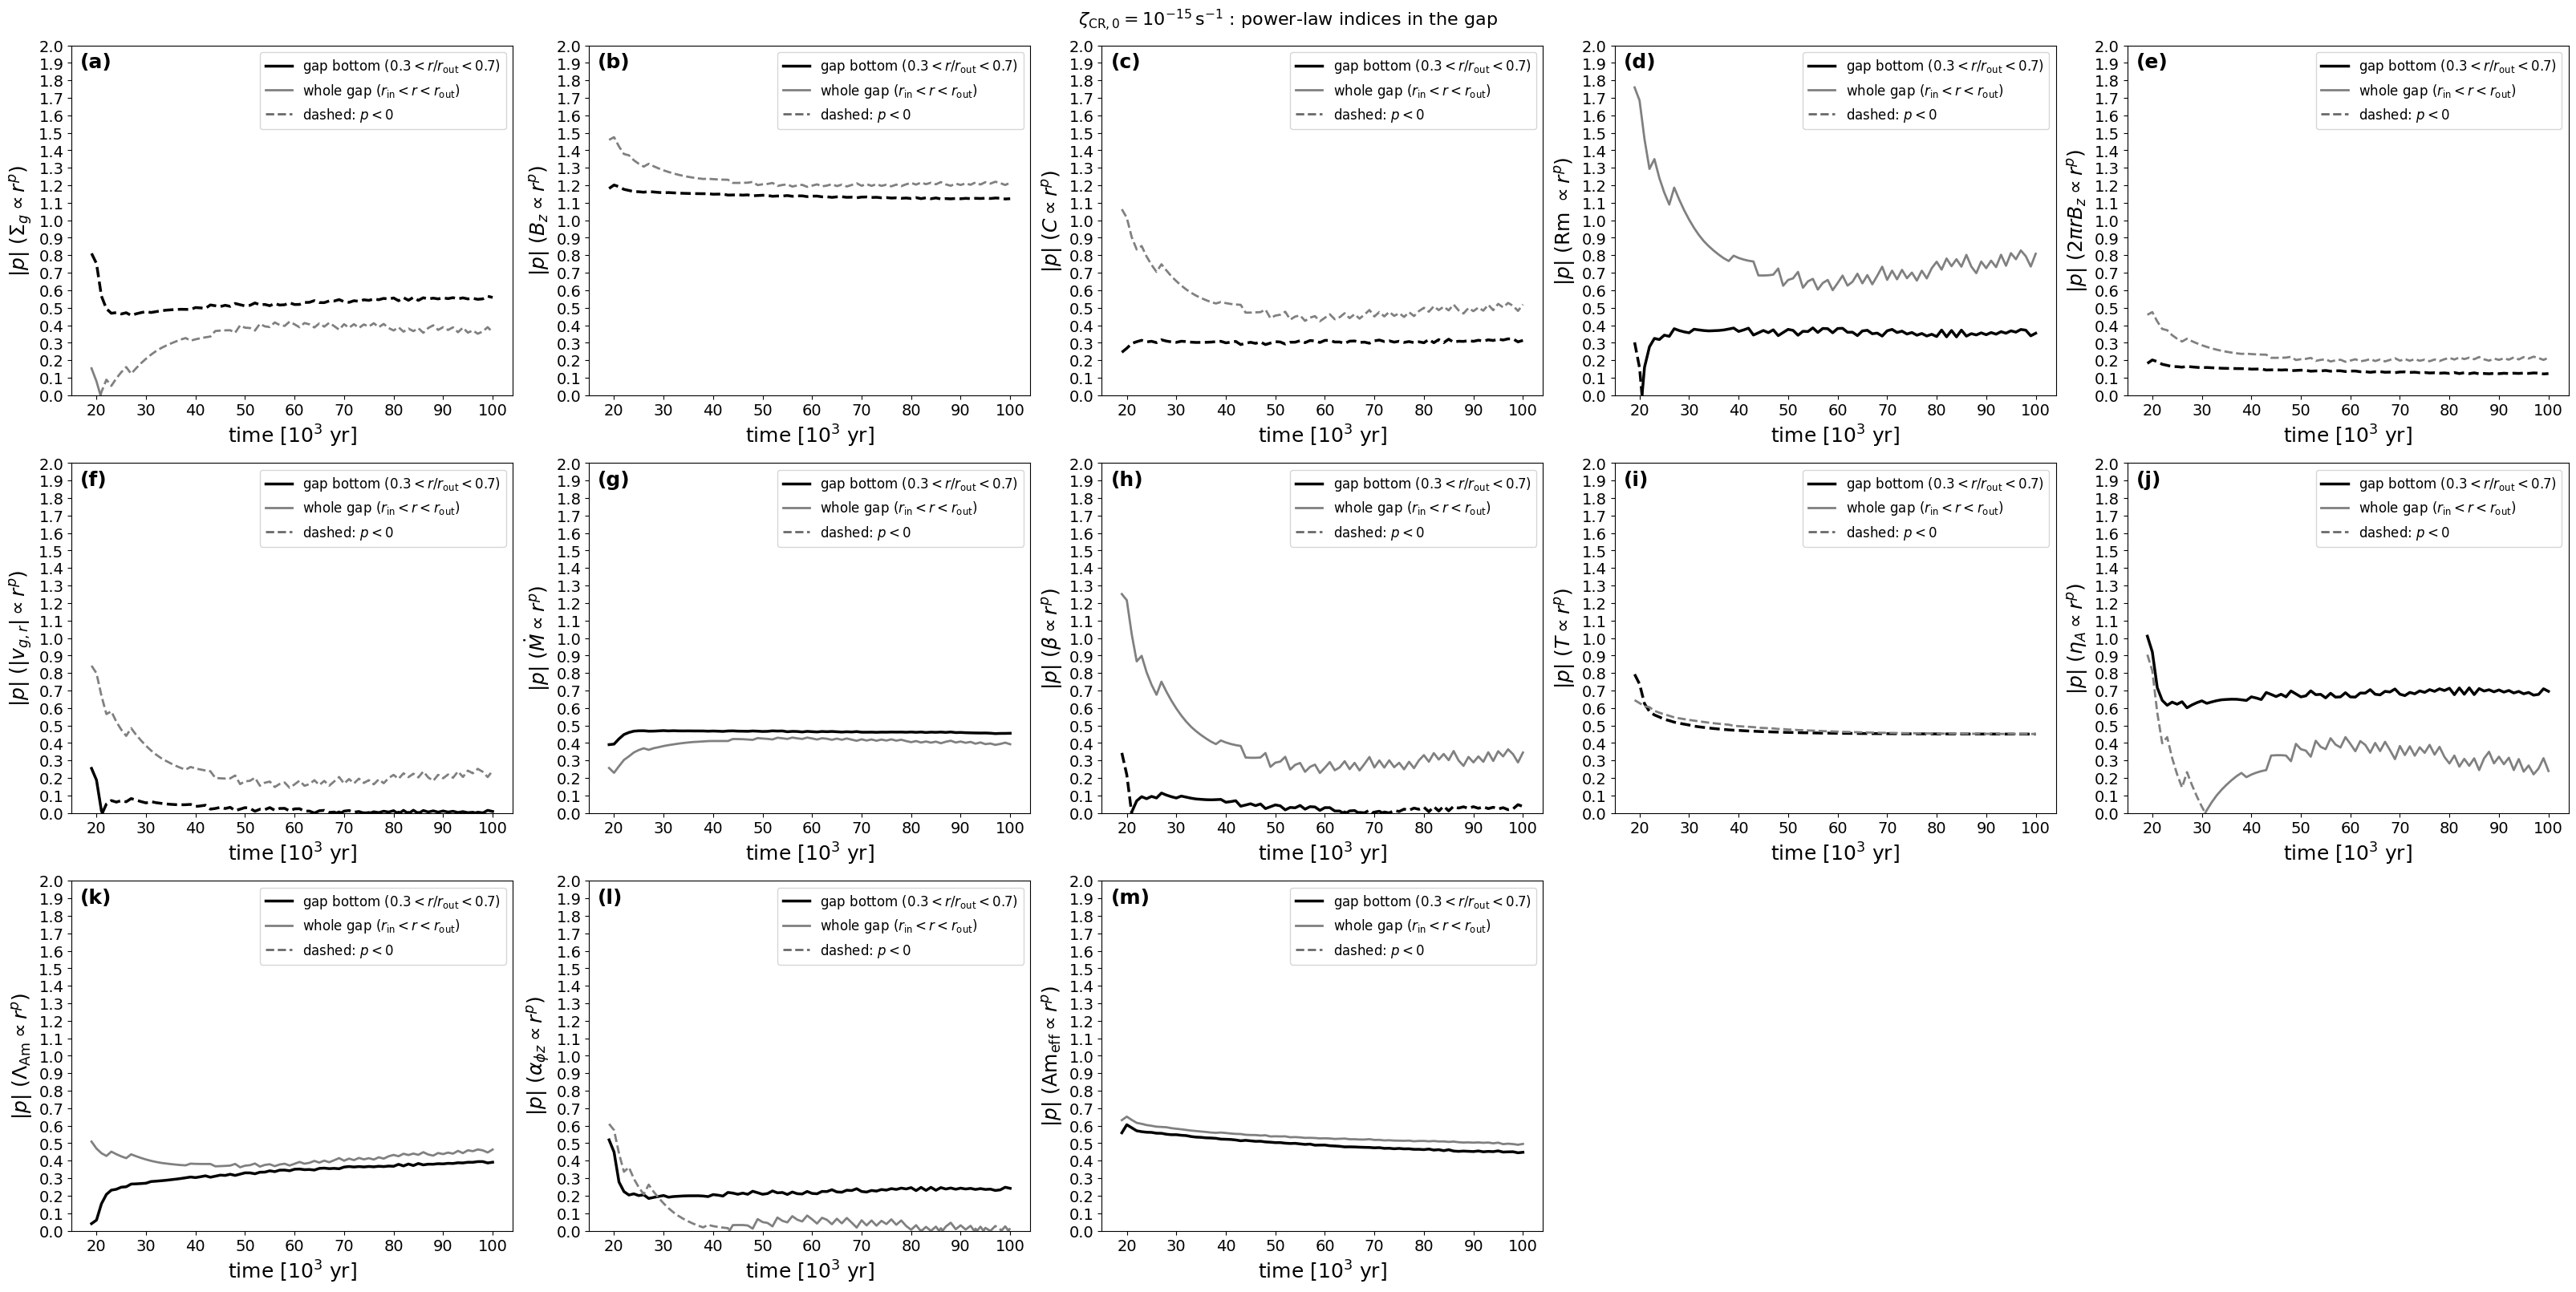

sig : gap bottom p = -0.529 (median), whole gap p = -0.372 (median)
B : gap bottom p = -1.137 (median), whole gap p = -1.211 (median)
C : gap bottom p = -0.305 (median), whole gap p = -0.486 (median)
Rm : gap bottom p = 0.359 (median), whole gap p = 0.735 (median)
flux : gap bottom p = -0.137 (median), whole gap p = -0.211 (median)
v : gap bottom p = -0.012 (median), whole gap p = -0.205 (median)
Mdot : gap bottom p = 0.464 (median), whole gap p = 0.411 (median)
beta : gap bottom p = 0.013 (median), whole gap p = 0.317 (median)
T : gap bottom p = -0.456 (median), whole gap p = -0.465 (median)
etaA : gap bottom p = 0.679 (median), whole gap p = 0.310 (median)
LamAm : gap bottom p = 0.346 (median), whole gap p = 0.407 (median)
alpha : gap bottom p = 0.224 (median), whole gap p = 0.023 (median)
Am : gap bottom p = 0.489 (median), whole gap p = 0.528 (median)


In [ ]:
# ======================================================
# ギャップ内の Sigma_g, B_z, C, Rm, 磁束, |v_g,r|, Mdot, beta, T, eta_A, Lambda_Am, alpha_phiz, Am_eff の冪指数 p (y = A (r/au)^p)
#   図1: t_show に最も近い時刻の動径分布 (実線) とフィット線 (黒破線). 凡例に p を表示. r_in を下向き, r_out を上向きの三角で示す
#   図2: 冪指数の時間進化 : ギャップ底 (fit_range: r/r_out, r > r_in のみ) と ギャップ全体 [r_in, r_out]. |p| を描く (p >= 0 は実線, p < 0 は破線)
# C = eta_tot/(r |v_g,r|) , Rm = c_s^2/(eta_tot Omega) , 磁束 = 2 pi r B_z , Mdot = -2 pi r Sigma_g v_g,r (内向き正)
# Lambda_Am = V_A^2/(eta_A Omega) , V_A^2 = B_z^2/(4 pi rho_mid) , rho_mid = Sigma_g/(sqrt(2 pi) H_g) , H_g = c_s/Omega (eta_A は上限なし)
# Am_eff の列がない出力では, そのパネルを空にする
# ln y と ln r の最小二乗 (np.polyfit). y > 0 のセルのみ使う (B_z, Mdot が負のセルは除く)
# v_g,r (C, |v_g,r|) と Mdot はなましをかけない出力の値をそのまま使う
# ギャップ全体は縁の急な変化を含むので 1 本の冪では表せない (参考)
# 上のセルの years, path_gas, path_mag, r_in_t, r_out_t, t_kyr, M_star, eta_max, use_eta_cap, model_names, resultdir を使う
#   -> 先に実行すること
# t >= t_gap_min のギャップが求まった時刻のみ使う
# file_gas 列: 0:r_cen 1:sigmag 4:vg_r 12:T 17:alpha_phiz(= 0.75 sqrt(2 pi) (H_g/r) alpha_DW) 23:Am_eff  (24:alpha_DW は使わない)     file_mag 列: 2:B_z 3:etaO_R 4:etaA_R 5:beta_disk
# ======================================================

# t_gap_min (これより前の時刻は使わない [kyr]) は thesis_common.ipynb で設定する
t_show = [30.0, 70.0, 94.0]       # 図1に描く時刻 [kyr]. 最も近い出力時刻を使う
fit_range = (0.3, 0.7)            # ギャップ底の範囲 (r/r_out)
show_colors = ["tab:blue", "tab:orange", "tab:green"]

def fit_power(r, y, sel):
    # sel のセルで y = A (r/au)^p を当てはめて (p, A) を返す. 点が足りなければ nan
    sel = sel & np.isfinite(y) & (y > 0.0)
    if np.count_nonzero(sel) < 3:
        return np.nan, np.nan
    p, lnA = np.polyfit(np.log(r[sel] / AU), np.log(y[sel]), 1)
    return p, np.exp(lnA)

def plot_signed(ax, t, p, color, lw, label):
    # |p| を描く. p >= 0 は実線, p < 0 は破線. 符号が変わるところは p = 0 の点を線形補間で入れて線をつなぐ
    k = np.where(p[:-1] * p[1:] < 0.0)[0]
    t0 = t[k] - p[k] * (t[k + 1] - t[k]) / (p[k + 1] - p[k])
    tt, pp = np.insert(t, k + 1, t0), np.insert(p, k + 1, 0.0)
    ax.plot(tt, np.where(pp >= 0.0, pp, np.nan), color=color, lw=lw, label=label)
    ax.plot(tt, np.where(pp <= 0.0, -pp, np.nan), color=color, lw=lw, ls="dashed")

def gap_quantities(year):
    # 時刻 year の r と, 冪指数を調べる量
    gas = np.loadtxt(path_gas + "/out{}_gas".format(year)).T
    r, sig, vgr, T = gas[0], gas[1], gas[4], gas[12]
    B, etaO, etaA, beta = np.loadtxt(path_mag + "/out{}_B".format(year), usecols=(2, 3, 4, 5)).T
    eta = np.minimum(etaO + etaA, eta_max) if use_eta_cap else etaO + etaA
    omega = np.sqrt(G * M_star / r**3)
    cs2 = kB * T / (mu * mH)
    v = np.abs(vgr)
    rho_mid = sig / (np.sqrt(2.0 * np.pi) * np.sqrt(cs2) / omega)
    no_col = np.full_like(r, np.nan)   # 列がない出力
    return r, {"sig": sig, "B": B, "C": eta / (r * v), "Rm": cs2 / (eta * omega), "flux": 2.0 * np.pi * r * B, "v": v,
               "Mdot": -2.0 * np.pi * r * sig * vgr,
               "beta": beta, "T": T, "etaA": etaA, "LamAm": B**2 / (4.0 * np.pi * rho_mid) / (etaA * omega),
               "alpha": gas[17], "Am": gas[23] if len(gas) > 23 else no_col}

use = np.isfinite(r_in_t) & np.isfinite(r_out_t) & (t_kyr >= t_gap_min)
if not np.any(use):
    raise ValueError("{} : 冪指数を求められる時刻がありません".format(resultdir))
quantities = [("sig", r"$\Sigma_g$ [g cm$^{-2}$]", r"$p$ ($\Sigma_g \propto r^p$)"),
              ("B", r"$B_z$ [G]", r"$p$ ($B_z \propto r^p$)"),
              ("C", r"$C$", r"$p$ ($C \propto r^p$)"),
              ("Rm", r"Rm", r"$p$ (Rm $\propto r^p$)"),
              ("flux", r"$2\pi r B_z$ [G cm]", r"$p$ ($2\pi r B_z \propto r^p$)"),
              ("v", r"$|v_{g,r}|$ [cm s$^{-1}$]", r"$p$ ($|v_{g,r}| \propto r^p$)"),
              ("Mdot", r"$\dot{M}$ [g s$^{-1}$]", r"$p$ ($\dot{M} \propto r^p$)"),
              ("beta", r"$\beta$", r"$p$ ($\beta \propto r^p$)"),
              ("T", r"$T$ [K]", r"$p$ ($T \propto r^p$)"),
              ("etaA", r"$\eta_A$ [cm$^2$ s$^{-1}$]", r"$p$ ($\eta_A \propto r^p$)"),
              ("LamAm", r"$\Lambda_{\rm Am}$", r"$p$ ($\Lambda_{\rm Am} \propto r^p$)"),
              ("alpha", r"$\alpha_{\phi z}$", r"$p$ ($\alpha_{\phi z} \propto r^p$)"),
              ("Am", r"${\rm Am}_{\rm eff}$", r"$p$ (${\rm Am}_{\rm eff} \propto r^p$)")]
p_bot = {key: np.full(len(years), np.nan) for key, _, _ in quantities}
p_all = {key: np.full(len(years), np.nan) for key, _, _ in quantities}
n_show = {int(np.flatnonzero(use)[np.argmin(np.abs(t_kyr[use] - ts))]): color for ts, color in zip(t_show, show_colors)}
r_lim = (0.5 * np.min(r_in_t[list(n_show)]) / AU, 2.0 * np.max(r_out_t[list(n_show)]) / AU)   # 図1の表示範囲 [au]
y_show = {key: [] for key, _, _ in quantities}   # 図1の縦軸の範囲を決める (表示範囲内の値)

fig, axes = plt.subplots(3, 5, figsize=(32, 16), layout="constrained")
axes = axes.ravel()
for ax in axes[len(quantities):]:
    ax.axis("off")
for n, year in enumerate(years):
    if not use[n]:
        continue
    r, ys = gap_quantities(year)
    r0, r1 = r_in_t[n], r_out_t[n]
    bot = (r > max(r0, fit_range[0] * r1)) & (r < fit_range[1] * r1)
    for ax, (key, _, _) in zip(axes, quantities):
        y = ys[key]
        p_bot[key][n], A = fit_power(r, y, bot)
        p_all[key][n], _ = fit_power(r, y, (r > r0) & (r < r1))
        if n in n_show:
            color = n_show[n]
            sel = (r / AU >= r_lim[0]) & (r / AU <= r_lim[1]) & np.isfinite(y) & (y > 0.0)
            y_show[key].append(y[sel])
            ax.plot(r / AU, np.where(np.isfinite(y) & (y > 0.0), y, np.nan), color=color, lw=2.5, label=r"$t = {:.0f}$ kyr, $p = {:.2f}$".format(t_kyr[n], p_bot[key][n]))
            ax.plot(r[bot] / AU, A * (r[bot] / AU)**p_bot[key][n], color="black", lw=2.0, ls="dashed", zorder=3)
            ax.scatter([r0 / AU], [np.interp(r0, r, y)], s=70, marker="v", color=color, edgecolor="black", zorder=4)
            ax.scatter([r1 / AU], [np.interp(r1, r, y)], s=70, marker="^", color=color, edgecolor="black", zorder=4)

for ax, (key, ylabel, _) in zip(axes, quantities):
    y_lim = np.concatenate(y_show[key])
    if len(y_lim) == 0:
        print("{} : {} の出力がないのでパネルを空にします".format(resultdir, key))
        ax.axis("off")
        continue
    ax.plot([], [], color="black", lw=2.0, ls="dashed", label="fit (gap bottom)")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(r_lim)
    ax.set_ylim(0.7 * np.min(y_lim), 1.5 * np.max(y_lim))
    ax.set_xlabel(r"$r$ [au]", fontsize=18)
    ax.set_ylabel(ylabel, fontsize=18)
    ax.tick_params(labelsize=14)
    ax.legend(fontsize=12, loc="best")
fig.suptitle(model_names[resultdir] + r" : radial profiles in the gap", fontsize=16)
plt.show()

fig, axes = plt.subplots(3, 5, figsize=(32, 16), layout="constrained")
axes = axes.ravel()
for ax in axes[len(quantities):]:
    ax.axis("off")
for ax, (key, _, plabel) in zip(axes, quantities):
    if not np.any(np.isfinite(p_all[key][use])):
        ax.axis("off")
        continue
    plot_signed(ax, t_kyr[use], p_bot[key][use], "black", 2.5,
                r"gap bottom (${:g} < r/r_{{\rm out}} < {:g}$)".format(*fit_range))
    plot_signed(ax, t_kyr[use], p_all[key][use], "gray", 2.0, r"whole gap ($r_{\rm in} < r < r_{\rm out}$)")
    ax.plot([], [], color="dimgray", lw=2.0, ls="dashed", label=r"dashed: $p < 0$")
    ax.set_xlabel(r"time [$10^3$ yr]", fontsize=18)
    ax.set_ylabel(plabel.replace("$p$", "$|p|$", 1), fontsize=18)
    ax.yaxis.set_major_locator(ptick.MultipleLocator(0.1))
    ax.set_ylim(0.0,2.0)
    ax.tick_params(labelsize=14)
    ax.legend(fontsize=12, loc="best")
fig.suptitle(model_names[resultdir] + r" : power-law indices in the gap", fontsize=16)
plt.show()

for key, _, _ in quantities:
    if not np.any(np.isfinite(p_all[key][use])):
        continue
    print("{} : gap bottom p = {:.3f} (median), whole gap p = {:.3f} (median)".format(key, np.nanmedian(p_bot[key][use]), np.nanmedian(p_all[key][use])))


## ギャップの底の解析解 (M4) とシミュレーションの比較

/tmp/ipykernel_247905/2984517981.py:49: RuntimeWarning: divide by zero encountered in divide
  return r, {"sig": sig, "B": B, "C": eta / (r * v), "Rm": cs2 / (eta * omega), "flux": 2.0 * np.pi * r * B, "v": v,
/tmp/ipykernel_247905/3878100526.py:113: RuntimeWarning: invalid value encountered in multiply
  ys["eta"] = ys["C"] * r * ys["v"]


   sig : M4 p =  -0.96 , sim p =  -0.56 (gap bottom) , |dp| = 0.40 , line at 12.6-29.2 au (sim p = -0.56)
     B : M4 p =  -1.00 , sim p =  -1.12 (gap bottom) , |dp| = 0.12 , line at 12.6-29.2 au (sim p = -1.12)
     v : M4 p =   0.46 , sim p =   0.01 (gap bottom) , |dp| = 0.45 , line at 12.6-29.2 au (sim p = 0.01)
   eta : M4 p =   1.46 , sim p =   0.70 (gap bottom) , |dp| = 0.76 , line at 12.6-29.2 au (sim p = 0.70)
     C : M4 p =   0.00 , sim p =  -0.31 (gap bottom) , |dp| = 0.31 , line at 12.6-29.2 au (sim p = -0.31)
    Rm : M4 p =  -0.41 , sim p =   0.35 (gap bottom) , |dp| = 0.76 , line at 12.6-29.2 au (sim p = 0.35)
  beta : M4 p =  -0.68 , sim p =  -0.04 (gap bottom) , |dp| = 0.65 , line at 12.6-29.2 au (sim p = -0.04)
    Am : M4 p =   0.38 , sim p =   0.45 (gap bottom) , |dp| = 0.06 , line at 12.6-29.2 au (sim p = 0.45)
 alpha : M4 p =   0.68 , sim p =   0.24 (gap bottom) , |dp| = 0.44 , line at 12.6-29.2 au (sim p = 0.24)

値の 3 倍判定 (t = 100 kyr, M4 は規格化なし). 中央値 = sim/M4 の中

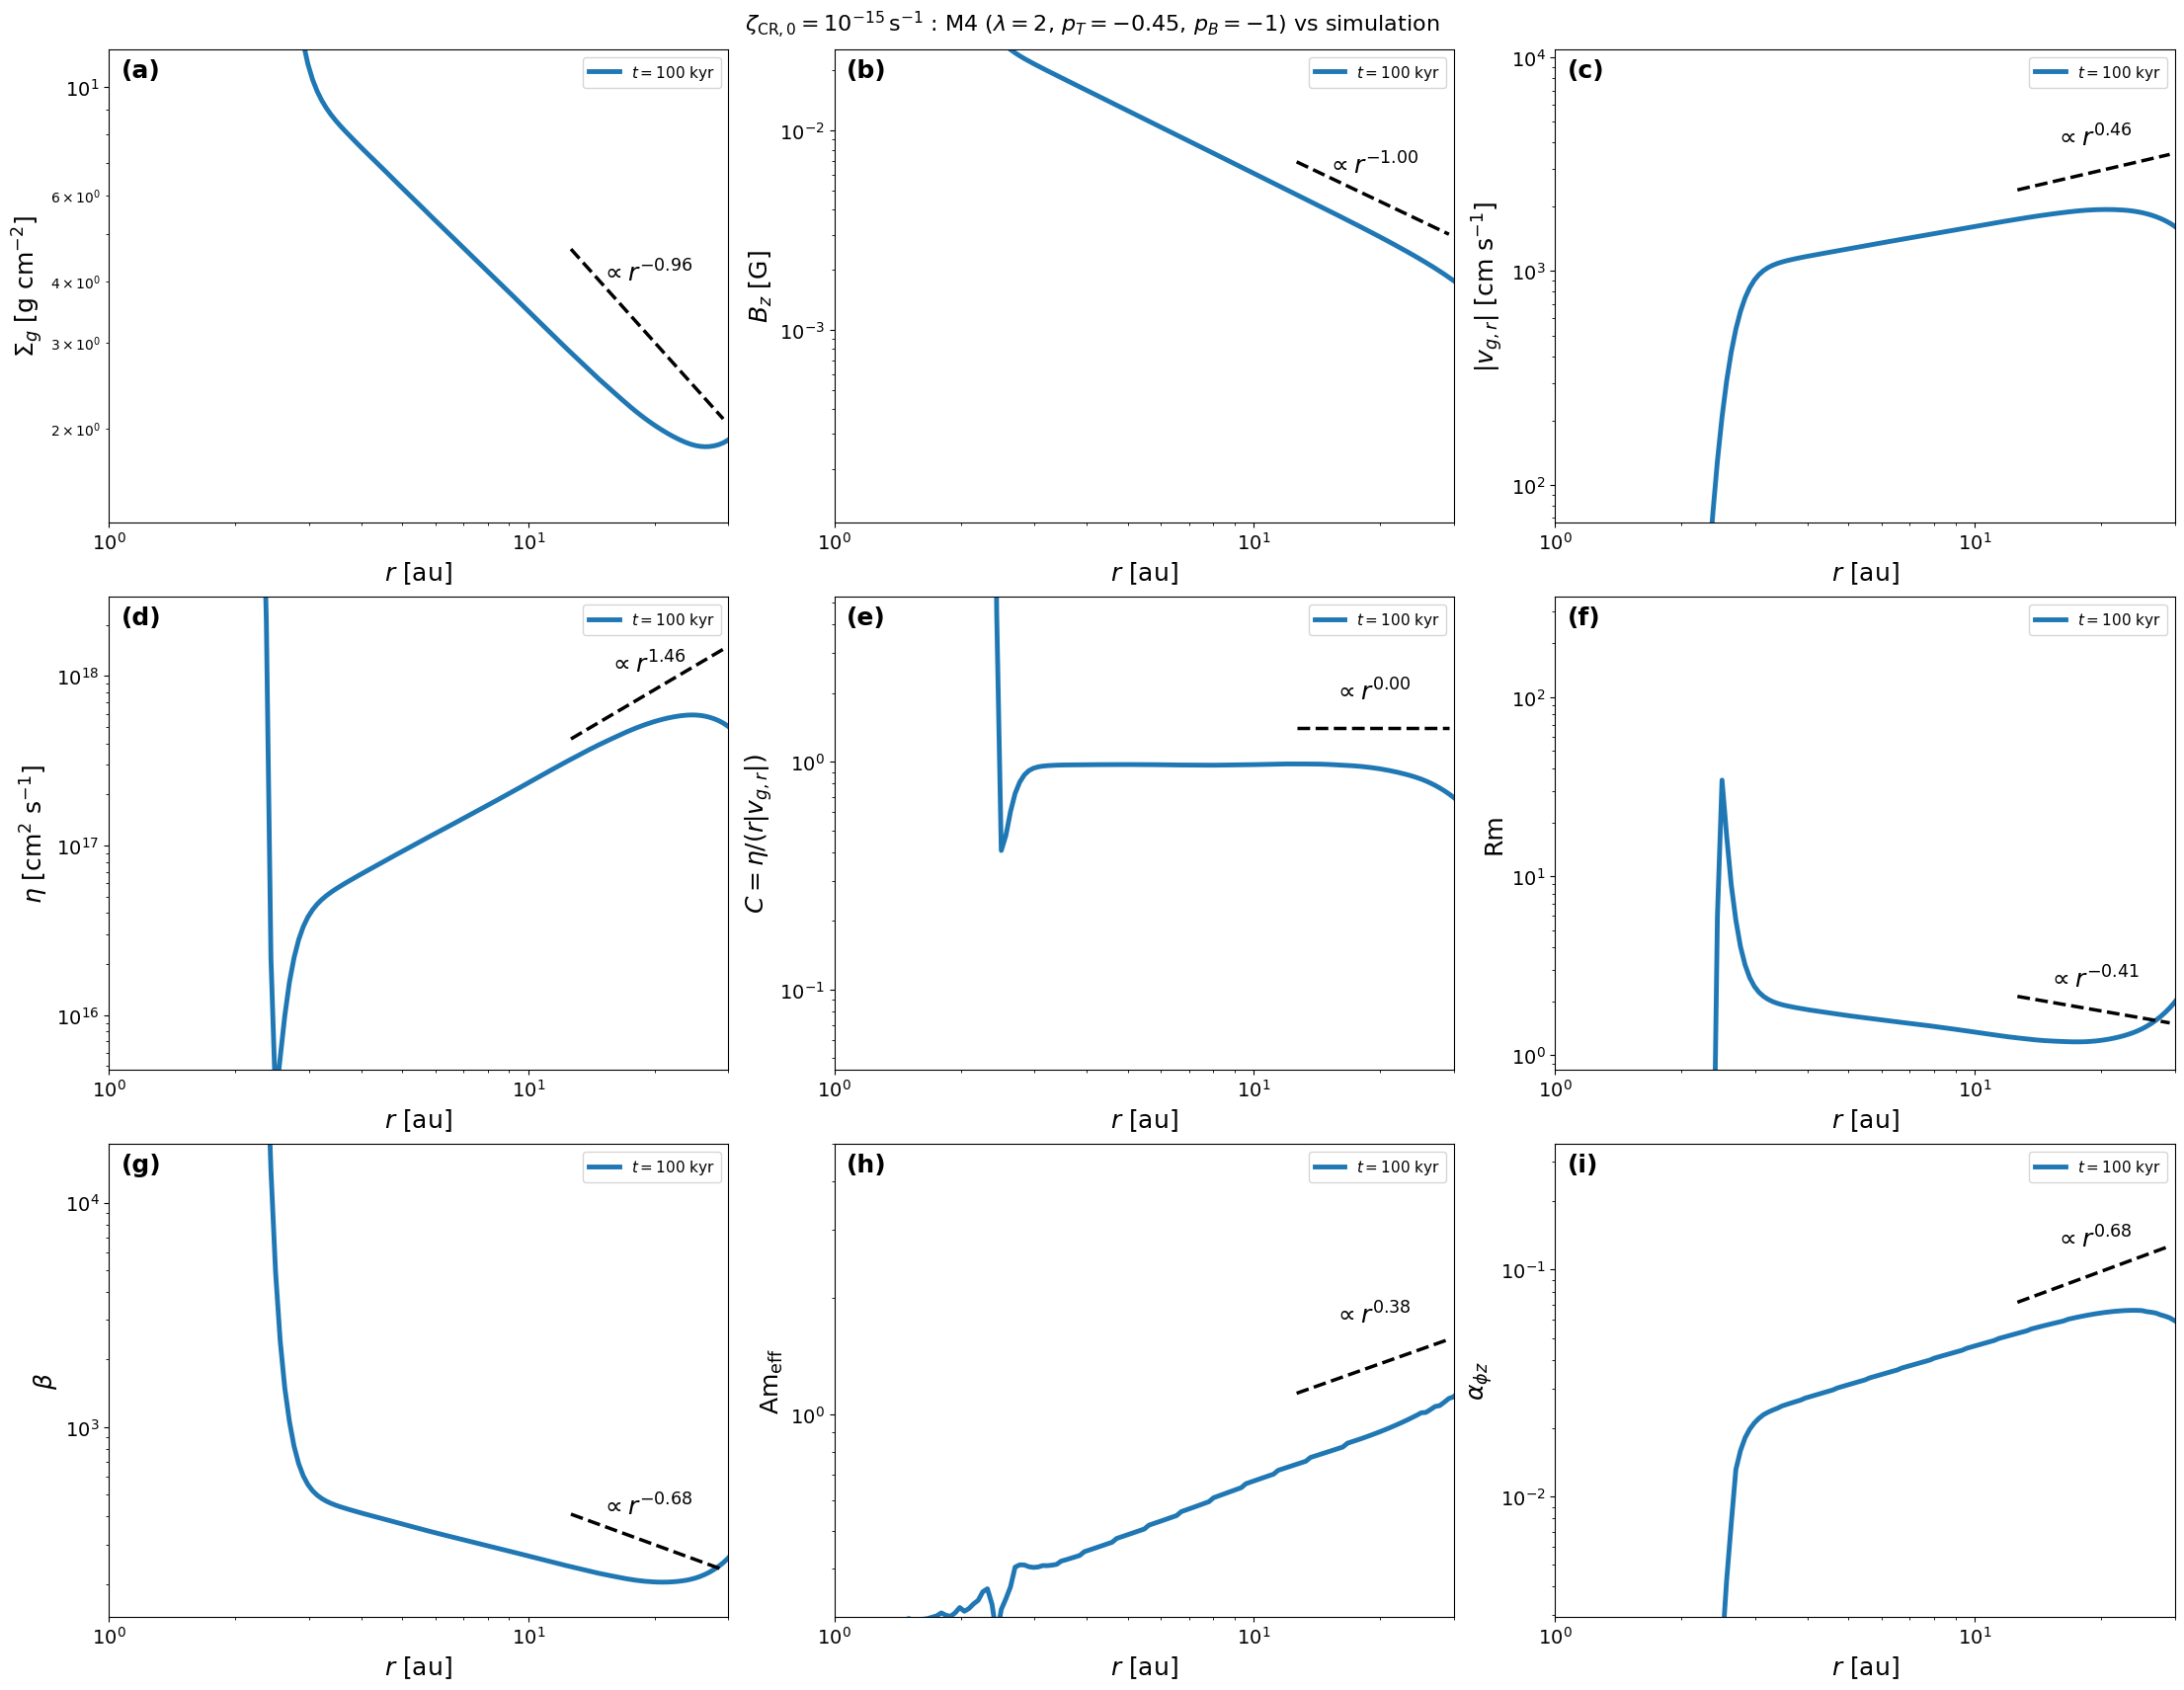

In [35]:
# ======================================================
# M4 解析解 (C = 1, rB_z 一定, 電離から計算した風トルク) の冪とシミュレーションの動径分布の比較 (Tsukamoto et al. 2023 の形式)
#   M4 の冪 (M4_analytic.pdf Eq. 3-8). X ∝ r^p_X , T ∝ r^p_T (= T_POW) , B_z ∝ r^p_B (= P_B)
#     p_Sigma + p_V = s - 1 , s = 1/[2(lambda - 1)]                (質量の定常, Mdot ∝ r^s)
#     p_rho = p_Sigma - 3/2 - p_T/2                                (rho_mid = Sigma_g Omega/(sqrt(2 pi) c_s))
#     p_Am = k p_rho + 3/2                                         (電離, Am_eff = A rho_mid^k/Omega)
#     p_beta = p_rho + p_T - 2 p_B                                 (beta = 8 pi rho_mid c_s^2/B_z^2)
#     p_V = p_T/2 - a p_beta + m p_Am                              (トルク則)
#       -> p_V = [(mk - a)(s - 1) + K]/(1 + mk - a) , K = p_T/2 (1 - a - mk) + 3/2 (a - mk + m) + 2 a p_B
#     p_eta = 1 + p_V (C = 1) , p_Rm = p_T + 3/2 - p_eta , p_alpha_phiz = p_V - p_T/2
#       (alpha_phiz = 0.75 sqrt(2 pi) h alpha_DW : コードの alpha_phiz (gas 列 17), V = 3/2 alpha_DW h c_s -> alpha_phiz = (sqrt(2 pi)/2) V/c_s)
#   シミュレーション : t_show_m4 の時刻 (t_ref_m4 を太線). 準定常の前の例として t_early_m4 を灰色で描く
#   M4 は傾きだけを比べる (値は合わせない, Tsukamoto et al. 2023 Fig. 4 のような冪の目安線).
#   t_ref_m4 のギャップ [r_in, r_out] の中の幅 win_m4 倍の窓に黒の破線を引く (曲線の offset_m4 倍の位置). その上に冪 (∝ r^p) を書く
#   窓の位置は LINE_POS_M4 で選ぶ:
#     "gap"  : ギャップの位置 r_gap (r_in < r < r_out で Sigma_g が最小の半径) を中心とする窓
#     "mid"  : r_in と r_out の中点を中心とする窓
#     "best" : 窓をずらしながら冪をフィットし, M4 の冪に最も近い窓
#   窓が取れなければギャップの底 (fit_range) に引く
#   値の 3 倍判定 (Tsukamoto et al. 2023 の基準): M4 を入力値 (M4_IN) から解いた値そのもの (規格化なし) と,
#   ギャップの底 / ギャップ全体の各セルのシミュレーションの値を比べ, sim/M4 がすべて 1/band_m4 ~ band_m4 に入るかを調べる
#   M4 の値 (M4_analytic.pdf Sec. 5): Mdot = Mdot0 (r/r0)^s , B_z = B_z0 (r/r0)^p_B , T = T0 (r/r0)^p_T , Delta 一様,
#     電離の規格化 A は r0 で V = V_Am_ref のとき Am_eff = Am_ref となるように決める.
#     トルク則 V = (3 A_E/2) (beta/1e4)^-a Am_eff^m Delta^1.2 c_s は beta ∝ 1/V, Am_eff ∝ V^-k なので
#     V^(1 - a + mk) = (V = 1 での右辺) と閉じた形で解ける. 以降 Sigma = Mdot/(2 pi r V), eta = r V (C = 1), Rm = c_s^2/(eta Omega),
#     alpha_phiz = (sqrt(2 pi)/2) V/c_s (= 0.75 sqrt(2 pi) h alpha_DW)
# 上の冪指数のセルの gap_quantities, fit_power, fit_range, years, r_in_t, r_out_t, t_kyr を使う -> 先に実行すること
# ======================================================

T_POW = -0.45                     # 温度の冪 (T ∝ r^T_POW)
P_B = -1.0                        # B_z の冪 (rB_z 一定なら -1)
lam_M4 = 2.0                      # 風の磁気レバーアーム
a_M4, m_M4, k_M4 = 0.73, 0.48, 0.5
t_ref_m4 = 100.0                   # 描く時刻 [kyr] (M4 の破線もこの時刻の曲線に置く). 最も近い出力時刻を使う
t_show_m4 = [t_ref_m4]            # 描く時刻 [kyr]. 複数にすると色分けして重ねる
colors_m4 = ["tab:blue", "tab:orange", "tab:green"]
t_early_m4 = None                 # 準定常の前の例 [kyr] (例: 20.0). None なら描かない
offset_m4 = 1.5                   # 破線を曲線から離す倍率 (窓の中心で曲線の offset_m4 倍)
win_m4 = 1.0                      # 破線を引く窓の幅 (r_hi/r_lo)
band_m4 = 3.0                     # 値の判定の倍率 (sim/M4 が 1/band_m4 ~ band_m4 なら一致)
# M4 の入力値 (M4_analytic.pdf Sec. 5.1: r = 10 au, 約 80 kyr の値)
M4_IN = dict(r0_au=10.0, Mdot0=8.0e18, flux0=7.5e12, T0=55.0, Delta=1.0, Am_ref=0.5, V_Am_ref=2.0e3, A_E=2.1e-3)
#   Mdot0 [g s^-1] , flux0 = 2 pi r0 B_z(r0) [G cm] , T0 [K] , Am_ref : V = V_Am_ref [cm s^-1] での Am_eff (r0)
LINE_POS_M4 = "mid"              # 破線の位置. "gap": r_gap 中心 , "mid": r_in と r_out の中点 , "best": 冪が最も近い窓

def m4_powers(pT, pB, lam=lam_M4, a=a_M4, m=m_M4, k=k_M4):
    # M4 の各量の冪
    s = 1.0 / (2.0 * (lam - 1.0))
    mk = m * k
    K = 0.5 * pT * (1.0 - a - mk) + 1.5 * (a - mk + m) + 2.0 * a * pB
    pV = ((mk - a) * (s - 1.0) + K) / (1.0 + mk - a)
    pS = s - 1.0 - pV
    prho = pS - 1.5 - 0.5 * pT
    peta = 1.0 + pV
    return {"sig": pS, "B": pB, "v": pV, "eta": peta, "C": 0.0, "Rm": pT + 1.5 - peta,
            "beta": prho + pT - 2.0 * pB, "Am": k * prho + 1.5, "alpha": pV - 0.5 * pT}

def nearest_year(t, need_gap):
    # t [kyr] に最も近い出力の番号 (need_gap なら r_in, r_out が求まった時刻から選ぶ)
    ok = np.isfinite(r_in_t) & np.isfinite(r_out_t) if need_gap else np.ones(len(years), dtype=bool)
    idx = np.flatnonzero(ok)
    return int(idx[np.argmin(np.abs(t_kyr[idx] - t))])

p_M4 = m4_powers(T_POW, P_B)
quantities_m4 = [("sig", r"$\Sigma_g$ [g cm$^{-2}$]"), ("B", r"$B_z$ [G]"), ("v", r"$|v_{g,r}|$ [cm s$^{-1}$]"),
                 ("eta", r"$\eta$ [cm$^2$ s$^{-1}$]"), ("C", r"$C = \eta/(r|v_{g,r}|)$"), ("Rm", r"Rm"),
                 ("beta", r"$\beta$"), ("Am", r"${\rm Am}_{\rm eff}$"), ("alpha", r"$\alpha_{\phi z}$")]

n_ref = nearest_year(t_ref_m4, True)
lines = [(nearest_year(ts, True), c, 3.5 if abs(ts - t_ref_m4) < 1e-6 else 2.0) for ts, c in zip(t_show_m4, colors_m4)]
if t_early_m4 is not None:
    lines.insert(0, (nearest_year(t_early_m4, False), "gray", 2.0))
r0_ref, r1_ref = r_in_t[n_ref], r_out_t[n_ref]
r_lim = (0.5 * np.nanmin([r_in_t[n] for n, _, _ in lines]) / AU, 2.0 * np.nanmax([r_out_t[n] for n, _, _ in lines]) / AU)

def m4_values(r, inp=M4_IN, pT=T_POW, pB=P_B, lam=lam_M4, a=a_M4, m=m_M4, k=k_M4):
    # M4 の各量の値 (規格化なし). r [cm] の配列
    s = 1.0 / (2.0 * (lam - 1.0))
    r0 = inp["r0_au"] * AU
    Om0 = np.sqrt(G * M_star / r0**3)
    cs0 = np.sqrt(kB * inp["T0"] / (mu * mH))
    rho_ref = inp["Mdot0"] / (2.0 * np.pi * r0 * inp["V_Am_ref"]) * Om0 / (np.sqrt(2.0 * np.pi) * cs0)
    A_ion = inp["Am_ref"] * Om0 / rho_ref**k
    Mdot = inp["Mdot0"] * (r / r0)**s
    Bz = inp["flux0"] / (2.0 * np.pi * r0) * (r / r0)**pB
    T = inp["T0"] * (r / r0)**pT
    cs2 = kB * T / (mu * mH)
    cs = np.sqrt(cs2)
    Om = np.sqrt(G * M_star / r**3)
    rho1 = Mdot / (2.0 * np.pi * r) * Om / (np.sqrt(2.0 * np.pi) * cs)   # V = 1 cm/s での rho_mid
    beta1 = 8.0 * np.pi * rho1 * cs2 / Bz**2
    Am1 = A_ion * rho1**k / Om
    V = (1.5 * inp["A_E"] * inp["Delta"]**1.2 * cs * (beta1 / 1.0e4)**(-a) * Am1**m)**(1.0 / (1.0 - a + m * k))
    eta = r * V
    h = cs / (r * Om)
    return {"sig": Mdot / (2.0 * np.pi * r * V), "B": Bz, "v": V, "eta": eta, "C": np.ones_like(r),
            "Rm": cs2 / (eta * Om), "beta": beta1 / V, "Am": Am1 * V**(-k), "alpha": 0.5 * np.sqrt(2.0 * np.pi) * V / cs}

def factor_check(r, y, sel, key):
    # sel のセルで sim/M4 (値そのもの) を比べ, (最大のずれの倍率, band_m4 以内のセルの割合, sim/M4 の中央値) を返す
    sel = sel & np.isfinite(y) & (y > 0.0)
    if np.count_nonzero(sel) < 1:
        return np.nan, np.nan, np.nan
    ratio = y[sel] / m4_values(r[sel])[key]
    dev = np.abs(np.log(ratio))
    return np.exp(np.max(dev)), np.mean(dev <= np.log(band_m4)), np.median(ratio)

check_rows = []
m4_lines = {}   # 破線の座標 (下の 2x2 の図で使う) : key -> (r [cm], y_M4, r_c [cm], 文字の高さ)

def with_eta(year):
    r, ys = gap_quantities(year)
    ys["eta"] = ys["C"] * r * ys["v"]
    return r, ys

fig, axes = plt.subplots(3, 3, figsize=(22, 17), layout="constrained")
axes = axes.ravel()
y_show = {key: [] for key, _ in quantities_m4}
for n, color, lw in lines:
    r, ys = with_eta(years[n])
    for ax, (key, _) in zip(axes, quantities_m4):
        y = np.where(np.isfinite(ys[key]) & (ys[key] > 0.0), ys[key], np.nan)
        sel = (r / AU >= r_lim[0]) & (r / AU <= r_lim[1]) & np.isfinite(y)
        y_show[key].append(y[sel])
        ax.plot(r / AU, y, color=color, lw=lw, label=r"$t = {:.0f}$ kyr".format(t_kyr[n]))
        if n == n_ref:
            # M4 の破線 : LINE_POS_M4 で選んだ窓に, 窓の中心で t_ref の曲線の offset_m4 倍の位置に置く
            bot = (r > max(r0_ref, fit_range[0] * r1_ref)) & (r < fit_range[1] * r1_ref)
            p_sim, _ = fit_power(r, ys[key], bot)
            gap = (r > r0_ref) & (r < r1_ref)
            win = bot
            if LINE_POS_M4 == "best":
                best = np.inf
                for j in np.flatnonzero(gap):
                    if r[j] * win_m4 > r1_ref:
                        break
                    w = gap & (r >= r[j]) & (r <= r[j] * win_m4)
                    p_w, _ = fit_power(r, ys[key], w)
                    if np.isfinite(p_w) and abs(p_w - p_M4[key]) < best:
                        win, best = w, abs(p_w - p_M4[key])
            elif LINE_POS_M4 in ("gap", "mid"):
                if LINE_POS_M4 == "gap":
                    g = np.flatnonzero(gap)
                    r_cen = r[g[np.nanargmin(ys["sig"][g])]] if len(g) > 0 else np.nan
                else:
                    r_cen = 0.5 * (r0_ref + r1_ref)
                w = gap & (r >= r_cen / np.sqrt(win_m4)) & (r <= r_cen * np.sqrt(win_m4))
                if np.count_nonzero(w) >= 2:
                    win = w
            else:
                raise ValueError("LINE_POS_M4 = {} は選べません".format(LINE_POS_M4))
            p_win, _ = fit_power(r, ys[key], win)
            ok = win & np.isfinite(y)
            if np.count_nonzero(ok) < 2:
                continue
            r_c = np.sqrt(r[ok][0] * r[ok][-1])
            y_c = np.exp(np.interp(np.log(r_c), np.log(r[ok]), np.log(y[ok])))
            y_m4 = offset_m4 * y_c * (r[ok] / r_c)**p_M4[key]
            ax.plot(r[ok] / AU, y_m4, color="black", lw=2.5, ls="dashed", zorder=5)
            m4_lines[key] = (r[ok], y_m4, r_c, offset_m4 * y_c * 1.25)
            ax.text(r_c / AU, offset_m4 * y_c * 1.25, r"$\propto r^{{{:.2f}}}$".format(p_M4[key]),
                    fontsize=18, ha="center", va="bottom", zorder=6)
            y_show[key].append(np.array([offset_m4 * y_c * 2.5]))
            print("{:>6s} : M4 p = {:6.2f} , sim p = {:6.2f} (gap bottom) , |dp| = {:.2f} , line at {:.1f}-{:.1f} au (sim p = {:.2f})".format(
                key, p_M4[key], p_sim, abs(p_M4[key] - p_sim), r[ok][0] / AU, r[ok][-1] / AU, p_win))
            check_rows.append((key, factor_check(r, ys[key], bot, key), factor_check(r, ys[key], gap, key)))

print("\n値の {:g} 倍判定 (t = {:.0f} kyr, M4 は規格化なし). 中央値 = sim/M4 の中央値, 最大のずれ = max(sim/M4, M4/sim), 割合 = {:g} 倍以内のセルの割合".format(
    band_m4, t_kyr[n_ref], band_m4))
print("M4 の入力:", M4_IN, ", p_T = {:g}, p_B = {:g}".format(T_POW, P_B))
print("{:>6s} | {:>40s} | {:>40s}".format("", "gap bottom ({:g}-{:g} r_out)".format(*fit_range), "whole gap [r_in, r_out]"))
for key, (dev_b, frac_b, med_b), (dev_g, frac_g, med_g) in check_rows:
    print("{:>6s} | med {:6.2f} , max {:7.2f}x , {:5.0%} , {:3s} | med {:6.2f} , max {:7.2f}x , {:5.0%} , {:3s}".format(
        key, med_b, dev_b, frac_b, "OK" if dev_b <= band_m4 else "NG", med_g, dev_g, frac_g, "OK" if dev_g <= band_m4 else "NG"))

for ax, (key, ylabel) in zip(axes, quantities_m4):
    y_lim = np.concatenate(y_show[key])
    y_lim = y_lim[np.isfinite(y_lim)]
    if len(y_lim) == 0:
        print("{} : {} の出力がないのでパネルを空にします".format(resultdir, key))
        ax.axis("off")
        continue
    ax.set_xscale("log")
    ax.set_yscale("log")
    # ax.set_xlim(r_lim)
    ax.set_xlim(1.0,30.0)
    ax.set_ylim(0.7 * np.min(y_lim), 1.5 * np.max(y_lim))
    ax.set_xlabel(r"$r$ [au]", fontsize=18)
    ax.set_ylabel(ylabel, fontsize=18)
    ax.tick_params(labelsize=14)
    ax.legend(fontsize=11, loc="best")
fig.suptitle(model_names[resultdir] + r" : analytic ($\lambda = {:g}$, $p_T = {:g}$, $p_B = {:g}$) vs simulation".format(lam_M4, T_POW, P_B), fontsize=16)
plt.show()


/tmp/ipykernel_247905/2984517981.py:49: RuntimeWarning: divide by zero encountered in divide
  return r, {"sig": sig, "B": B, "C": eta / (r * v), "Rm": cs2 / (eta * omega), "flux": 2.0 * np.pi * r * B, "v": v,
/tmp/ipykernel_247905/3878100526.py:113: RuntimeWarning: invalid value encountered in multiply
  ys["eta"] = ys["C"] * r * ys["v"]


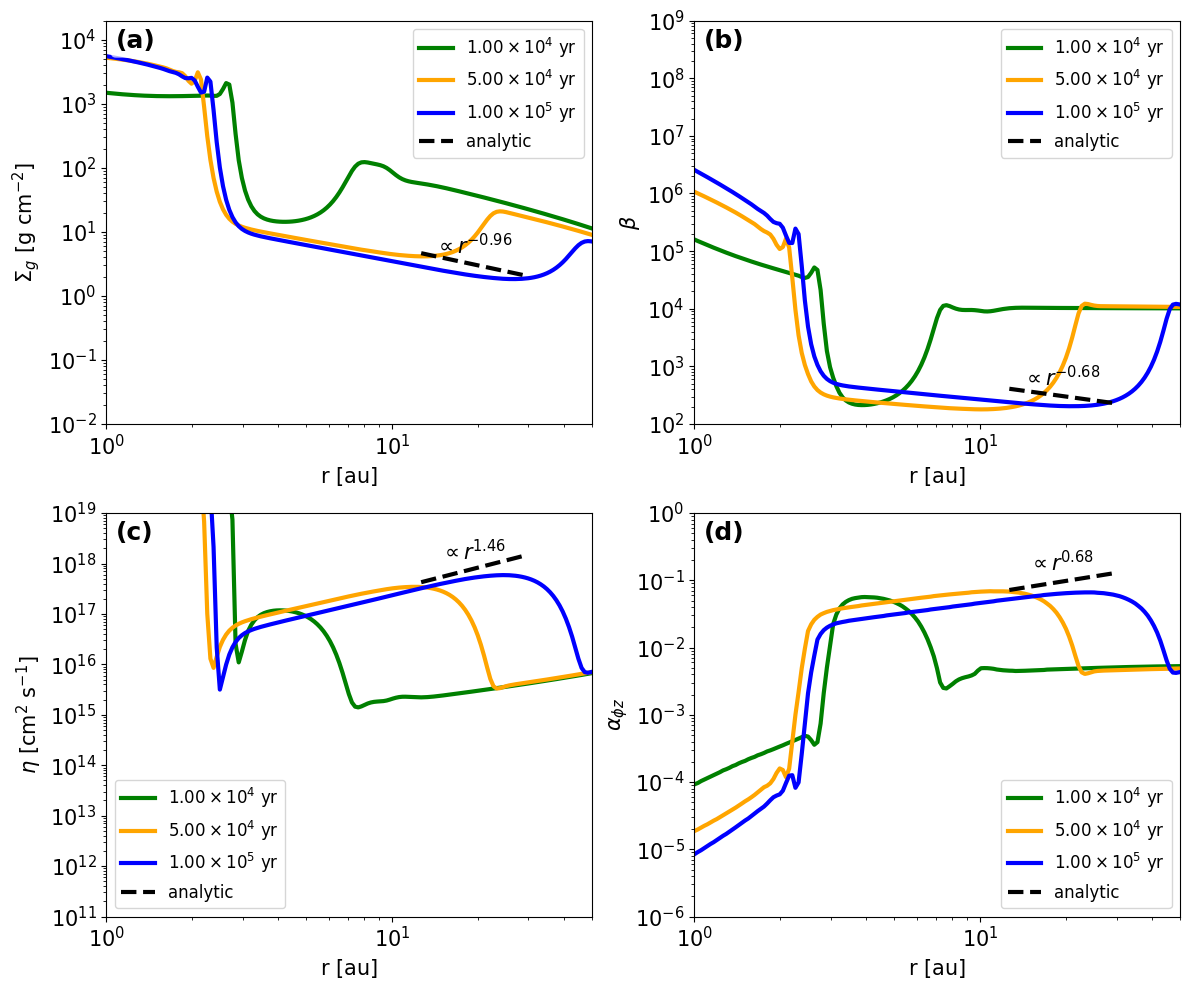

In [38]:
# ======================================================
# Sigma_g, beta, eta, alpha_phiz の動径分布と M4 の冪の線 (2x2). 文字・目盛り・凡例の大きさは analysis_snapshot.ipynb の 2x2 の図に合わせる
# 上の M4 のセルの n_ref, with_eta, p_M4, m4_lines を使う -> 先に実行すること (破線の位置の決め方は上のセルと同じ)
# ======================================================

xlim_p4 = (1.0, 50.0)   # 横軸の範囲 [au]
# 縦軸の範囲 (パネルごと). None なら表示範囲のデータから自動で決める. 主目盛りはどのパネルも 1 桁ごと
ylim_p4 = {"sig": (1.0e-2,2.0e4),     # Sigma_g [g cm^-2]
           "beta": (1.0e2,1.0e9),     # beta (中心面)
           "eta": (1.0e11,1.0e19),    # eta = eta_O + eta_A (eta_max で上限) [cm^2 s^-1]
           "alpha": (1.0e-6,1.0e0)}  # alpha_phiz
times_p4 = [1.0e4, 5.0e4, 1.0e5]              # 描く時刻 [yr] (最も近い出力時刻を使う). M4 の破線は t_ref_m4 の曲線に置く
colors_p4 = ["green", "orange", "blue"]       # 時刻ごとの色 (1e4, 1e5 yr は analysis_snapshot.ipynb の SNAP_COLORS と同じ)

def year_label(year):
    # analysis_snapshot.ipynb の snap_label と同じ書き方. 例: 10000 -> $1.00\times10^{4}\ \rm{yr}$
    if year == 0:
        return r"$0\ \rm{yr}$"
    n = int(np.floor(np.log10(year)))
    return r"${:.2f}\times10^{{{}}}\ \rm{{yr}}$".format(year / 10**n, n)
panels_p4 = [("sig", r"$ \Sigma_g \ [\rm{g \ cm^{-2}}] $"), ("beta", r"$ \beta $"),
             ("eta", r"$ \eta \ [\rm{cm^{2} \ s^{-1}}] $"), ("alpha", r"$ \alpha_{\phi z} $")]

profiles_p4 = []
for ts, color in zip(times_p4, colors_p4):
    year = min(years, key=lambda y: abs(y - ts))
    profiles_p4.append((year, color) + with_eta(year))

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (key, ylabel) in zip(axes.ravel(), panels_p4):
    y_lim = []
    for year, color, r, ys in profiles_p4:
        y = np.where(np.isfinite(ys[key]) & (ys[key] > 0.0), ys[key], np.nan)
        ax.plot(r / AU, y, color=color, lw=3, label=year_label(year))
        sel = (r / AU >= xlim_p4[0]) & (r / AU <= xlim_p4[1]) & np.isfinite(y)
        y_lim += list(y[sel])
    if key in m4_lines:
        r_l, y_l, r_c, y_txt = m4_lines[key]
        ax.plot(r_l / AU, y_l, color="black", lw=3, ls="dashed", label="analytic")
        ax.text(r_c / AU, y_txt, r"$\propto r^{{{:.2f}}}$".format(p_M4[key]), fontsize=15, ha="center", va="bottom", clip_on=True)   # 軸の外に出たら描かない (tight_layout が崩れないように)
        y_lim += list(y_l) + [2.0 * y_txt]
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(xlim_p4)
    ax.set_ylim(ylim_p4[key] if ylim_p4.get(key) is not None else (0.7 * np.nanmin(y_lim), 1.5 * np.nanmax(y_lim)))
    ax.yaxis.set_major_locator(ptick.LogLocator(base=10.0, numticks=100))   # 主目盛りを 1 桁ごとに (間引かない)
    ax.yaxis.set_minor_locator(ptick.LogLocator(base=10.0, subs=np.arange(2, 10) * 0.1, numticks=100))
    ax.yaxis.set_minor_formatter(ptick.NullFormatter())
    ax.set_xlabel(r"$ \rm{r} \ \rm{[au]}$", fontsize=15)
    ax.set_ylabel(ylabel, fontsize=15)
    ax.tick_params(labelsize=15)
    ax.legend(fontsize=12, loc="best")
plt.tight_layout()
plt.show()
